# Milestone 1: Formula 1 Podium Prediction Companion

This is the complete, self-contained Kaggle submission notebook. Every function used for loading, auditing, cleaning, joining, feature engineering, modeling, evaluation, experimentation, explainability, plotting, and inference appears in visible cells below. The notebook does **not** import project code from `pipeline.py`.

The prediction cutoff is after qualifying and before the race starts. The unit of analysis is one driver entering one race, and the binary target is `positionOrder <= 3`. PR-AUC is primary because podiums are rare; ROC-AUC is secondary. F1, precision, and recall are calculated at thresholds selected from validation data only.

## 0. Kaggle setup

Attach the public **Formula 1 World Championship (1950-2024)** Kaggle dataset containing the 14 CSV files, then choose **Run All**. No source ZIP or repository module is needed. The raw CSV files are read only and never modified.

In [1]:
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

def locate_data() -> Path:
    '''Find the raw CSV directory locally or in Kaggle's attached inputs.'''
    # Use the repository data locally. On Kaggle, find the folder containing
    # results.csv instead of relying on the generated dataset path.
    local = ROOT / "data" / "raw"
    if (local / "results.csv").exists():
        return local
    kaggle_root = Path("/kaggle/input")
    matches = sorted(kaggle_root.rglob("results.csv")) if kaggle_root.exists() else []
    if not matches:
        raise FileNotFoundError("Attach the Formula 1 dataset containing results.csv.")
    return matches[0].parent

DATA = locate_data()
OUT = Path("/kaggle/working/artifacts") if Path("/kaggle/working").exists() else ROOT / "artifacts"
OUT.mkdir(parents=True, exist_ok=True)
print(f"Raw data: {DATA}")
print(f"Generated artifacts: {OUT}")

Raw data: C:\Users\yehia\Desktop\Semester 9\ACL\ACL-9th-Paladin\data\raw
Generated artifacts: C:\Users\yehia\Desktop\Semester 9\ACL\ACL-9th-Paladin\artifacts


## 1. Imports, analytical contract, and relational schema

The constants define the features, primary keys, and foreign-key relationships used throughout the analysis.

In [2]:
from __future__ import annotations

import functools
import json
import re
import warnings
from pathlib import Path
from typing import Any

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.experimental import enable_iterative_imputer  # noqa: F401  (activates IterativeImputer)
from sklearn.impute import IterativeImputer, KNNImputer, SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

SENTINEL = "\\N"

# Piazza ruling on removing rows: ``positionText == "F"`` marks a driver who did not
# qualify, did not prequalify, or failed the 107% rule. That is settled before the race
# starts, so the driver never entered it and the row may be removed. ``W`` (withdrew) rows
# may NOT be removed: the code is only known after the race, and grid 0 can also be a
# real pit-lane start. The rows are dropped before any feature is built, so a skipped
# weekend never counts as a race in the form windows or in the field size.
DID_NOT_ENTER_CODE = "F"

FEATURE_GROUPS = {
    "grid": ["grid_position", "pit_lane_start", "front_row", "field_size"],
    "qualifying": ["qualifying_position", "qualifying_time_seconds", "qualifying_missing"],
    "form": ["driver_podium_rate_5", "constructor_podium_rate_5", "driver_races_before"],
    "standings": ["driver_points_before", "driver_rank_before", "constructor_points_before", "constructor_rank_before"],
    # `round` was removed after context_feature_experiment showed it changes validation
    # PR-AUC by far less than the network's seed spread in every model. `year` stays.
    "context": ["driver_age", "year"],
}
FEATURES = [feature for group in FEATURE_GROUPS.values() for feature in group]

PRIMARY_KEYS = {
    "circuits": ["circuitId"], "constructors": ["constructorId"],
    "constructor_results": ["constructorResultsId"],
    "constructor_standings": ["constructorStandingsId"],
    "drivers": ["driverId"], "driver_standings": ["driverStandingsId"],
    "races": ["raceId"], "results": ["resultId"],
    "qualifying": ["qualifyId"], "seasons": ["year"], "status": ["statusId"],
}

FOREIGN_KEYS = [
    ("races", "circuitId", "circuits", "circuitId"),
    ("results", "raceId", "races", "raceId"),
    ("results", "driverId", "drivers", "driverId"),
    ("results", "constructorId", "constructors", "constructorId"),
    ("results", "statusId", "status", "statusId"),
    ("qualifying", "raceId", "races", "raceId"),
    ("qualifying", "driverId", "drivers", "driverId"),
    ("driver_standings", "raceId", "races", "raceId"),
    ("constructor_standings", "raceId", "races", "raceId"),
]

## 2. Loading, auditing, cleaning, and feature engineering

Literal `\N` values become missing values. Dates and qualifying durations receive semantic types. Shared-drive duplicates are resolved deterministically before leakage-safe historical features are constructed.

In [3]:
def load_raw_tables(data_dir: str | Path) -> dict[str, pd.DataFrame]:
    """Load the supplied CSV files and treat the literal ``\\N`` as missing."""
    data_dir = Path(data_dir)
    tables = {}
    for path in sorted(data_dir.glob("*.csv")):
        tables[path.stem] = pd.read_csv(path, na_values=[SENTINEL], low_memory=False)
    # Fail early here instead of getting a harder-to-read merge error later.
    required = set(PRIMARY_KEYS) | {"sprint_results", "lap_times", "pit_stops"}
    missing = required - tables.keys()
    if missing:
        raise FileNotFoundError(f"Missing required tables: {sorted(missing)}")
    return tables


def audit_tables(tables: dict[str, pd.DataFrame]) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Check declared keys and return separate primary-key and foreign-key tables."""
    pk_rows = []
    for table, cols in PRIMARY_KEYS.items():
        frame = tables[table]
        pk_rows.append({"table": table, "key": "+".join(cols),
                        "rows": len(frame), "null_keys": int(frame[cols].isna().any(axis=1).sum()),
                        "duplicate_keys": int(frame.duplicated(cols).sum())})
    fk_rows = []
    for child, col, parent, parent_col in FOREIGN_KEYS:
        values = tables[child][col].dropna()
        # Any child value missing from the parent table is an orphaned reference.
        orphan = ~values.isin(tables[parent][parent_col].dropna())
        fk_rows.append({"relationship": f"{child}.{col} -> {parent}.{parent_col}",
                        "checked": len(values), "orphans": int(orphan.sum())})
    return pd.DataFrame(pk_rows), pd.DataFrame(fk_rows)


def _time_to_seconds(value: Any) -> float:
    """Convert a qualifying time such as ``1:23.456`` to seconds."""
    if pd.isna(value):
        return np.nan
    text = str(value).strip()
    # Minutes are optional because some files store short times as plain seconds.
    match = re.fullmatch(r"(?:(\d+):)?(\d+(?:\.\d+)?)", text)
    if not match:
        return np.nan
    minutes = int(match.group(1) or 0)
    return minutes * 60 + float(match.group(2))


def clean_results(results: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Resolve shared-drive duplicates deterministically.

    We retain the car the driver actually started (grid > 0), then the best final
    classification, then the smallest resultId. This is reproducible and preserves
    the pre-race identity of the entrant whenever possible.
    """
    # Keep the downloaded table unchanged so the audit can still use the raw rows.
    frame = results.copy()
    frame["_started"] = frame["grid"].fillna(0).gt(0)
    counts = frame.groupby(["raceId", "driverId"]).size().rename("rows").reset_index()
    duplicates = counts[counts["rows"] > 1].copy()
    frame = frame.sort_values(
        ["raceId", "driverId", "_started", "positionOrder", "resultId"],
        ascending=[True, True, False, True, True], na_position="last",
    )
    # The sort puts the preferred row first within each driver-race group.
    clean = frame.drop_duplicates(["raceId", "driverId"], keep="first").drop(columns="_started")
    assert not clean.duplicated(["raceId", "driverId"]).any()
    return clean, duplicates


def _previous_standings(standings: pd.DataFrame, races: pd.DataFrame, entity: str) -> pd.DataFrame:
    """Move post-race standings forward so they describe the next race's starting state."""
    columns = ["raceId", entity, "points", "position"]
    s = standings[columns].merge(races[["raceId", "year", "round"]], on="raceId", how="left")
    s = s.sort_values([entity, "year", "round"])
    # A standings row is recorded after a race, so attach it to the next round.
    # Using it on the same race would leak the result we are trying to predict.
    s["next_raceId"] = s.groupby([entity, "year"])["raceId"].shift(-1)
    prefix = "driver" if entity == "driverId" else "constructor"
    return s.dropna(subset=["next_raceId"])[["next_raceId", entity, "points", "position"]].rename(
        columns={"next_raceId": "raceId", "points": f"{prefix}_points_before", "position": f"{prefix}_rank_before"}
    ).assign(raceId=lambda x: x.raceId.astype(int))


def build_modeling_table(tables: dict[str, pd.DataFrame],
                         drop_did_not_enter: bool = True) -> tuple[pd.DataFrame, dict[str, Any]]:
    """Build one pre-race feature row per driver and return cleaning diagnostics.

    Shared drives are resolved first, then the drivers who did not enter the race
    (``DID_NOT_ENTER_CODE``) are removed before any feature is computed. Pass
    ``drop_did_not_enter=False`` to keep them; the non-starter audit and experiment use that
    version to show what the decision changes.
    """
    races = tables["races"].copy()
    races["date"] = pd.to_datetime(races["date"], errors="coerce")
    results, duplicate_groups = clean_results(tables["results"])
    rows_after_shared_drives = len(results)
    if drop_did_not_enter:
        results = results[results["positionText"].ne(DID_NOT_ENTER_CODE)].copy()

    # Start from cleaned race results, then add the entities needed for features
    # and the three analysis questions.
    base = results.merge(races[["raceId", "year", "round", "date", "circuitId", "name"]], on="raceId", validate="many_to_one")
    base = base[base["year"].between(1950, 2024)].copy()
    base = base.merge(tables["drivers"][["driverId", "dob", "nationality"]].rename(columns={"nationality": "driver_nationality"}), on="driverId", validate="many_to_one")
    base = base.merge(tables["constructors"][["constructorId", "name"]].rename(columns={"name": "constructor_name"}), on="constructorId", validate="many_to_one")
    base = base.merge(tables["circuits"][["circuitId", "name", "country"]].rename(columns={"name": "circuit_name"}), on="circuitId", validate="many_to_one")
    base["dob"] = pd.to_datetime(base["dob"], errors="coerce")
    base["driver_age"] = (base["date"] - base["dob"]).dt.days / 365.2425
    base["podium"] = base["positionOrder"].le(3).astype(int)
    # Grid 0 means a pit-lane or exceptional start. Store it separately so zero is
    # not treated as a position ahead of pole.
    base["grid_position"] = base["grid"].where(base["grid"].gt(0))
    base["pit_lane_start"] = base["grid"].eq(0).astype(int)
    base["front_row"] = base["grid"].isin([1, 2]).astype(int)
    base["field_size"] = base.groupby("raceId")["driverId"].transform("size")

    qualifying = tables["qualifying"].copy()
    # Use the driver's best recorded session time. Older races often have no
    # qualifying row, so missingness is kept as its own feature.
    for col in ["q1", "q2", "q3"]:
        qualifying[col + "_seconds"] = qualifying[col].map(_time_to_seconds)
    qualifying["qualifying_time_seconds"] = qualifying[["q1_seconds", "q2_seconds", "q3_seconds"]].min(axis=1)
    qualifying = qualifying.sort_values(["raceId", "driverId", "position", "qualifyId"]).drop_duplicates(["raceId", "driverId"])
    base = base.merge(qualifying[["raceId", "driverId", "position", "qualifying_time_seconds"]].rename(columns={"position": "qualifying_position"}), on=["raceId", "driverId"], how="left", validate="one_to_one")
    base["qualifying_missing"] = base["qualifying_position"].isna().astype(int)

    dprev = _previous_standings(tables["driver_standings"], races, "driverId")
    cprev = _previous_standings(tables["constructor_standings"], races, "constructorId")
    base = base.merge(dprev, on=["raceId", "driverId"], how="left", validate="one_to_one")
    base = base.merge(cprev, on=["raceId", "constructorId"], how="left", validate="many_to_one")

    # No standings row yet means nothing has been scored yet this season: round 1,
    # a driver's or team's first race of the season, or 1950-1957 for constructors
    # (their championship began in 1958). The true value is 0 points, not an unknown
    # value for the median imputer to guess.
    for who in ["driver", "constructor"]:
        base[f"{who}_points_before"] = base[f"{who}_points_before"].fillna(0)
        base[f"{who}_rank_before"] = base[f"{who}_rank_before"].fillna(0)

    base = base.sort_values(["date", "raceId", "driverId"]).reset_index(drop=True)
    # Shift before rolling so a driver's current result cannot enter its own feature.
    base["driver_podium_rate_5"] = base.groupby("driverId")["podium"].transform(lambda s: s.shift().rolling(5, min_periods=1).mean())
    # Aggregate both cars at race level before shifting. A row-level shift could let
    # one teammate see the other teammate's result from the same race.
    constructor_races = (base.groupby(["constructorId", "raceId", "date"], as_index=False)
                         .podium.mean().sort_values(["constructorId", "date", "raceId"]))
    constructor_races["constructor_podium_rate_5"] = constructor_races.groupby("constructorId")["podium"].transform(
        lambda s: s.shift().rolling(5, min_periods=1).mean())
    base = base.merge(constructor_races[["constructorId", "raceId", "constructor_podium_rate_5"]],
                      on=["constructorId", "raceId"], how="left", validate="many_to_one")
    base["driver_races_before"] = base.groupby("driverId").cumcount()

    diagnostics = {
        "raw_result_rows": int(len(tables["results"])),
        "duplicate_driver_race_groups": int(len(duplicate_groups)),
        "rows_after_shared_drive_resolution": int(rows_after_shared_drives),
        "did_not_enter_rows_removed": int(rows_after_shared_drives - len(results)),
        "clean_rows": int(len(base)),
        "unique_grain": bool(not base.duplicated(["raceId", "driverId"]).any()),
        "year_min": int(base.year.min()), "year_max": int(base.year.max()),
    }
    return base, diagnostics


SPLIT_YEARS = {"train": (1950, 2019), "validation": (2020, 2021), "test": (2022, 2024)}

## 3. EDA, chronological splitting, preprocessing, and models

Training covers 1950-2019, validation 2020-2021, and test 2022-2024. Preprocessing is fitted on training rows only, and all three models use identical rows and features.

In [4]:
def split_by_time(frame: pd.DataFrame) -> dict[str, pd.DataFrame]:
    """Create fixed chronological train, validation, and test periods."""
    return {name: frame[frame.year.between(first, last)].copy()
            for name, (first, last) in SPLIT_YEARS.items()}


def split_summary(frame: pd.DataFrame) -> pd.DataFrame:
    """Describe the size, period, target rate, and missingness of each split."""
    rows = []
    for name, part in split_by_time(frame).items():
        rows.append({
            "split": name,
            "years": f"{int(part.year.min())}-{int(part.year.max())}",
            "first_race": part.date.min().date().isoformat(),
            "last_race": part.date.max().date().isoformat(),
            "rows": int(len(part)),
            "share_of_rows": len(part) / len(frame),
            "races": int(part.raceId.nunique()),
            "drivers": int(part.driverId.nunique()),
            "starters_per_race": len(part) / part.raceId.nunique(),
            "podiums": int(part.podium.sum()),
            "podium_rate": float(part.podium.mean()),
            "qualifying_missing": float(part.qualifying_missing.mean()),
        })
    return pd.DataFrame(rows)


def split_integrity(frame: pd.DataFrame) -> pd.DataFrame:
    """Check that the split is complete, disjoint, and strictly ordered in time."""
    splits = split_by_time(frame)
    train, val, test = splits["train"], splits["validation"], splits["test"]
    races = {name: set(part.raceId) for name, part in splits.items()}
    checks = {
        "every row assigned to exactly one split": sum(len(p) for p in splits.values()) == len(frame),
        "no race shared by train and validation": not races["train"] & races["validation"],
        "no race shared by validation and test": not races["validation"] & races["test"],
        "no race shared by train and test": not races["train"] & races["test"],
        "last training race before first validation race": train.date.max() < val.date.min(),
        "last validation race before first test race": val.date.max() < test.date.min(),
        "both classes present in every split": all(p.podium.nunique() == 2 for p in splits.values()),
    }
    return pd.DataFrame({"check": list(checks), "passed": [bool(v) for v in checks.values()]})


def split_strategy_experiment(frame: pd.DataFrame, random_state: int = 42) -> pd.DataFrame:
    """Compare the chronological split with two random alternatives.

    Each strategy holds out the same number of rows as the validation seasons and
    trains the logistic baseline on the rest. The leakage columns show what a random
    split lets the model see that would not exist on a real race morning.
    """
    rng = np.random.default_rng(random_state)
    chrono = split_by_time(frame)
    holdout_size = len(chrono["validation"])
    # Hold out whole races so one strategy is random in time but not split inside a race.
    race_ids = frame.raceId.unique()
    shuffled = rng.permutation(race_ids)
    race_sizes = frame.groupby("raceId").size().loc[shuffled]
    held_races = set(race_sizes.index[race_sizes.cumsum() <= holdout_size])
    random_rows = frame.index[rng.permutation(len(frame))[:holdout_size]]
    strategies = {
        "chronological (used)": (chrono["train"], chrono["validation"]),
        "random races": (frame[~frame.raceId.isin(held_races)], frame[frame.raceId.isin(held_races)]),
        "random rows": (frame.drop(index=random_rows), frame.loc[random_rows]),
    }
    rows = []
    for name, (train, held) in strategies.items():
        model = clone(model_definitions(random_state)["Logistic regression"])
        model.fit(train[FEATURES], train.podium)
        p = model.predict_proba(held[FEATURES])[:, 1]
        rows.append({
            "strategy": name,
            "train_rows": int(len(train)),
            "held_out_rows": int(len(held)),
            "held_out_years": f"{int(held.year.min())}-{int(held.year.max())}",
            "held_out_podium_rate": float(held.podium.mean()),
            # Same-race leakage: another row from the held-out row's race sits in training.
            "held_out_races_also_in_train": float(held.raceId.isin(set(train.raceId)).mean()),
            # Future leakage: training contains seasons later than the held-out row.
            "held_out_rows_with_future_training": float(held.year.lt(train.year.max()).mean()),
            "PR-AUC": float(average_precision_score(held.podium, p)),
            "ROC-AUC": float(roc_auc_score(held.podium, p)),
        })
    return pd.DataFrame(rows)


def cleaning_eda(raw_results: pd.DataFrame, cleaned: pd.DataFrame) -> pd.DataFrame:
    """Compare row counts and key rates at each cleaning stage.

    Three stages show what each step does on its own: the raw results, the table after
    shared drives are resolved (the grain fix), and the final modeling table after the
    drivers who did not enter the race are removed.
    """
    raw = raw_results.copy()
    deduplicated, _ = clean_results(raw_results)
    stages = [("Raw results", raw),
              ("Shared drives resolved", deduplicated),
              ("Modeling table (F rows removed)", cleaned)]
    rows = []
    for stage, data in stages:
        podium = data["positionOrder"].le(3)
        rows.append({
            "stage": stage,
            "rows": int(len(data)),
            "unique_driver_races": int(data[["raceId", "driverId"]].drop_duplicates().shape[0]),
            "duplicate_rows": int(data.duplicated(["raceId", "driverId"], keep=False).sum()),
            "podium_rate": float(podium.mean()),
            "pit_lane_share": float(data["grid"].eq(0).mean()),
            "missing_finish_share": float(data["positionOrder"].isna().mean()),
            "median_grid": float(data.loc[data["grid"].gt(0), "grid"].median()),
        })
    return pd.DataFrame(rows)


def _pipeline(model: Any, scale: bool = True, strategy: str = "median") -> Pipeline:
    """Wrap a model with imputation and optional scaling fitted on training data."""
    steps = [("imputer", SimpleImputer(strategy=strategy, fill_value=0))]
    if scale:
        steps.append(("scaler", StandardScaler()))
    return Pipeline([("preprocess", Pipeline(steps)), ("model", model)])


def model_definitions(random_state: int = 42) -> dict[str, Pipeline]:
    """Return the three candidate models with reproducible settings.

    The forest and the network use settings chosen with ``hyperparameter_search`` on
    validation: depth 12 with leaf size 30 for the forest (its starting settings, an
    unlimited depth with leaf size 4, memorized the training seasons), and a stronger
    regularization of 0.02 for the network. Neither is the top of its grid in every run:
    the gaps to the best setting are inside the seed and race noise, so they are kept as
    the more constrained choices. Logistic regression kept its starting settings because
    the top settings tie within 0.0005.
    """
    return {
        "Logistic regression": _pipeline(LogisticRegression(max_iter=2000, solver="liblinear", class_weight="balanced", random_state=random_state)),
        "Random forest": _pipeline(RandomForestClassifier(n_estimators=240, max_depth=12, min_samples_leaf=30, class_weight="balanced_subsample", n_jobs=1, random_state=random_state), scale=False),
        "Shallow neural network": _pipeline(MLPClassifier(hidden_layer_sizes=(32, 12), alpha=0.02, early_stopping=True, max_iter=300, random_state=random_state)),
    }


def _best_threshold(y: pd.Series, probability: np.ndarray) -> float:
    """Choose the validation threshold with the highest F1 score."""
    candidates = np.linspace(0.05, 0.80, 151)
    # Threshold selection uses validation predictions only. The test set stays out.
    scores = [f1_score(y, probability >= value, zero_division=0) for value in candidates]
    return float(candidates[int(np.argmax(scores))])


def _metrics(y: pd.Series, probability: np.ndarray, threshold: float) -> dict[str, float]:
    """Calculate ranking metrics and threshold-based classification metrics."""
    prediction = probability >= threshold
    return {
        "ROC-AUC": float(roc_auc_score(y, probability)),
        "PR-AUC": float(average_precision_score(y, probability)),
        "F1": float(f1_score(y, prediction, zero_division=0)),
        "Precision": float(precision_score(y, prediction, zero_division=0)),
        "Recall": float(recall_score(y, prediction, zero_division=0)),
    }


def train_and_evaluate(frame: pd.DataFrame, random_state: int = 42) -> tuple[dict[str, Pipeline], pd.DataFrame, dict[str, float]]:
    """Fit each candidate on training years and score every chronological split."""
    splits = split_by_time(frame)
    trained, rows, thresholds = {}, [], {}
    for name, model in model_definitions(random_state).items():
        model.fit(splits["train"][FEATURES], splits["train"]["podium"])
        # Each model gets its own cutoff because their probability scales differ.
        val_probability = model.predict_proba(splits["validation"][FEATURES])[:, 1]
        threshold = _best_threshold(splits["validation"]["podium"], val_probability)
        thresholds[name] = threshold
        trained[name] = model
        for split_name, split in splits.items():
            probability = model.predict_proba(split[FEATURES])[:, 1]
            rows.append({"model": name, "split": split_name, "threshold": threshold,
                         **_metrics(split["podium"], probability, threshold)})
    return trained, pd.DataFrame(rows), thresholds


def preprocessing_experiments(frame: pd.DataFrame) -> pd.DataFrame:
    """Compare imputation and scaling choices using validation scores only."""
    splits = split_by_time(frame)
    variants = {
        "median + scaling": _pipeline(LogisticRegression(max_iter=2000, solver="liblinear", class_weight="balanced", random_state=42), True, "median"),
        "median, no scaling": _pipeline(LogisticRegression(max_iter=2000, solver="liblinear", class_weight="balanced", random_state=42), False, "median"),
        "zero + scaling": _pipeline(LogisticRegression(max_iter=2000, solver="liblinear", class_weight="balanced", random_state=42), True, "constant"),
    }
    rows = []
    for name, model in variants.items():
        model.fit(splits["train"][FEATURES], splits["train"].podium)
        p = model.predict_proba(splits["validation"][FEATURES])[:, 1]
        rows.append({"preprocessing": name, "validation_ROC-AUC": roc_auc_score(splits["validation"].podium, p),
                     "validation_PR-AUC": average_precision_score(splits["validation"].podium, p)})
    return pd.DataFrame(rows)


def preprocessing_effects(frame: pd.DataFrame) -> pd.DataFrame:
    """Measure what median imputation and scaling do to every feature.

    Both steps are fitted on training rows. Validation and test pass through the
    same fitted transform, so their scaled means show the shift between periods.
    """
    splits = split_by_time(frame)
    train = splits["train"][FEATURES]
    imputer = SimpleImputer(strategy="median").fit(train)
    imputed = pd.DataFrame(imputer.transform(train), columns=FEATURES, index=train.index)
    scaler = StandardScaler().fit(imputed)
    scaled = pd.DataFrame(scaler.transform(imputed), columns=FEATURES, index=train.index)

    def later_scaled(name: str) -> pd.DataFrame:
        """Apply the training-fitted imputer and scaler to a later split."""
        filled = pd.DataFrame(imputer.transform(splits[name][FEATURES]), columns=FEATURES)
        return pd.DataFrame(scaler.transform(filled), columns=FEATURES)

    val_scaled, test_scaled = later_scaled("validation"), later_scaled("test")
    rows = []
    for i, f in enumerate(FEATURES):
        rows.append({
            "feature": f,
            "missing_share": float(train[f].isna().mean()),
            "fill_value": float(imputer.statistics_[i]),
            "raw_min": float(train[f].min()), "raw_max": float(train[f].max()),
            "raw_mean": float(train[f].mean()), "raw_std": float(train[f].std()),
            "imputed_mean": float(imputed[f].mean()), "imputed_std": float(imputed[f].std()),
            # Filling many rows with one value shrinks the spread of that feature.
            "std_change_from_imputation": float(imputed[f].std() / train[f].std() - 1),
            "scaled_min": float(scaled[f].min()), "scaled_max": float(scaled[f].max()),
            "scaled_mean": float(scaled[f].mean()), "scaled_std": float(scaled[f].std()),
            "validation_scaled_mean": float(val_scaled[f].mean()),
            "test_scaled_mean": float(test_scaled[f].mean()),
        })
    return pd.DataFrame(rows)


def feature_engineering_effects(frame: pd.DataFrame, tables: dict[str, pd.DataFrame]) -> pd.DataFrame:
    """Compare raw source columns with the engineered features built from them."""
    qualifying = tables["qualifying"]
    raw_times = qualifying[["q1", "q2", "q3"]]
    parsed = pd.concat([raw_times[c].map(_time_to_seconds) for c in raw_times], axis=1)
    pairs = [
        ("grid (raw)", frame["grid"]),
        ("grid_position (0 -> missing)", frame["grid_position"]),
        ("pit_lane_start (grid == 0)", frame["pit_lane_start"]),
        ("q1/q2/q3 text present", raw_times.notna().any(axis=1).astype(float)),
        ("best qualifying seconds (parsed)", parsed.min(axis=1)),
        ("qualifying_time_seconds (joined)", frame["qualifying_time_seconds"]),
        ("driver_podium_rate_5 (shifted)", frame["driver_podium_rate_5"]),
        ("driver_points_before (previous race)", frame["driver_points_before"]),
    ]
    rows = []
    for name, values in pairs:
        values = pd.to_numeric(values, errors="coerce")
        rows.append({"column": name, "rows": int(len(values)),
                     "missing_share": float(values.isna().mean()),
                     "zero_share": float(values.eq(0).mean()),
                     "min": float(values.min()), "median": float(values.median()),
                     "max": float(values.max()), "mean": float(values.mean())})
    return pd.DataFrame(rows)


def _ordered_preprocessor(order: str) -> Pipeline:
    """Return imputation and scaling steps in the requested order."""
    median = ("imputer", SimpleImputer(strategy="median"))
    zero = ("imputer", SimpleImputer(strategy="constant", fill_value=0))
    scale = ("scaler", StandardScaler())
    steps = {
        "impute -> scale": [median, scale],
        "scale -> impute": [scale, median],
        "zero-fill -> scale": [zero, scale],
        "scale -> zero-fill": [scale, zero],
    }[order]
    return Pipeline(steps)


PREPROCESSING_ORDERS = [
    # (experiment, order, fit preprocessing on)
    ("A: impute vs scale first", "impute -> scale", "train"),
    ("A: impute vs scale first", "scale -> impute", "train"),
    ("B: zero-fill vs scale first", "zero-fill -> scale", "train"),
    ("B: zero-fill vs scale first", "scale -> zero-fill", "train"),
    ("C: split vs preprocess first", "impute -> scale", "all years (before split)"),
]


def preprocessing_order_experiments(frame: pd.DataFrame, random_state: int = 42) -> pd.DataFrame:
    """Swap the order of preprocessing steps and score each order on validation.

    Experiment A swaps median imputation and scaling. Experiment B swaps zero-filling
    and scaling, where order changes the value written into missing cells. Experiment C
    fits the preprocessing before splitting, which lets later seasons set the medians
    and scaling statistics used in training.
    """
    splits = split_by_time(frame)
    train, val = splits["train"], splits["validation"]
    base_models = model_definitions(random_state)
    rows = []
    for experiment, order, fitted_on in PREPROCESSING_ORDERS:
        pre = _ordered_preprocessor(order)
        pre.fit(frame[FEATURES] if fitted_on.startswith("all") else train[FEATURES])
        X_train, X_val = pre.transform(train[FEATURES]), pre.transform(val[FEATURES])
        # Express the value given to a missing cell in original units for two features.
        scaler = pre.named_steps["scaler"]
        filled = pre.transform(pd.DataFrame([{f: np.nan for f in FEATURES}]))[0] * scaler.scale_ + scaler.mean_
        for model_name in ["Logistic regression", "Shallow neural network"]:
            model = clone(base_models[model_name].named_steps["model"]).fit(X_train, train.podium)
            p = model.predict_proba(X_val)[:, 1]
            rows.append({
                "experiment": experiment, "order": order, "preprocessing_fitted_on": fitted_on,
                "model": model_name,
                "missing_grid_position_becomes": float(filled[FEATURES.index("grid_position")]),
                "missing_qualifying_time_becomes": float(filled[FEATURES.index("qualifying_time_seconds")]),
                "train_std_qualifying_time": float(X_train[:, FEATURES.index("qualifying_time_seconds")].std()),
                "validation_PR-AUC": float(average_precision_score(val.podium, p)),
                "validation_ROC-AUC": float(roc_auc_score(val.podium, p)),
            })
    result = pd.DataFrame(rows)
    # Compare each order with the first order of the same experiment and model.
    first = result.groupby(["experiment", "model"])["validation_PR-AUC"].transform("first")
    result["PR-AUC_change_vs_reference"] = result["validation_PR-AUC"] - first
    reference = result[result.experiment.str.startswith("A") & result.order.eq("impute -> scale")]
    reference = reference.set_index("model")["validation_PR-AUC"]
    # Experiment C has a single row per model, so compare it with the fit-on-train run.
    leaky = result.experiment.str.startswith("C")
    result.loc[leaky, "PR-AUC_change_vs_reference"] = (
        result.loc[leaky, "validation_PR-AUC"] - result.loc[leaky, "model"].map(reference))
    return result


def preprocessing_plots(frame: pd.DataFrame, effects: pd.DataFrame, out_dir: str | Path) -> dict[str, str]:
    """Plot feature distributions and ranges before and after preprocessing."""
    out = Path(out_dir); out.mkdir(parents=True, exist_ok=True)
    sns.set_theme(style="whitegrid", context="notebook")
    splits = split_by_time(frame)
    train = splits["train"][FEATURES]
    imputer = SimpleImputer(strategy="median").fit(train)
    imputed = pd.DataFrame(imputer.transform(train), columns=FEATURES)
    scaler = StandardScaler().fit(imputed)
    scaled = pd.DataFrame(scaler.transform(imputed), columns=FEATURES)
    val_filled = pd.DataFrame(imputer.transform(splits["validation"][FEATURES]), columns=FEATURES)
    val_scaled = pd.DataFrame(scaler.transform(val_filled), columns=FEATURES)
    shown = ["grid_position", "qualifying_time_seconds", "driver_points_before", "constructor_podium_rate_5"]

    fig, axes = plt.subplots(2, len(shown), figsize=(15, 6.5))
    for j, f in enumerate(shown):
        # Top row: the imputed column has a spike at the training median.
        bins = np.histogram_bin_edges(imputed[f], bins=40)
        axes[0, j].hist(imputed[f], bins=bins, color="#e76f51", alpha=0.55, label="after median imputation")
        axes[0, j].hist(train[f].dropna(), bins=bins, color="#264653", alpha=0.7, label="raw (observed)")
        axes[0, j].axvline(imputer.statistics_[FEATURES.index(f)], color="black", ls="--", lw=1)
        axes[0, j].set_title(f"{f}\n{train[f].isna().mean():.0%} missing in training")
        axes[0, j].set_yscale("log")
        # Bottom row: training is centred at zero; validation shows the later-season shift.
        bins = np.histogram_bin_edges(np.r_[scaled[f], val_scaled[f]], bins=40)
        axes[1, j].hist(scaled[f], bins=bins, density=True, color="#2a9d8f", alpha=0.6, label="training, scaled")
        axes[1, j].hist(val_scaled[f], bins=bins, density=True, color="#f4a261", alpha=0.6, label="validation, same transform")
        axes[1, j].axvline(0, color="black", lw=1)
        axes[1, j].set_xlabel("standardized value")
    axes[0, 0].set_ylabel("rows (log)"); axes[1, 0].set_ylabel("density")
    axes[0, 0].legend(fontsize=8); axes[1, 0].legend(fontsize=8)
    fig.suptitle("Effect of median imputation (top) and training-fitted scaling (bottom)")
    fig.tight_layout(); fig.savefig(out / "preprocessing_distributions.png", dpi=150, bbox_inches="tight"); plt.close(fig)

    fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
    order = effects.sort_values("raw_std")["feature"]
    e = effects.set_index("feature").loc[order]
    axes[0].barh(order, e.raw_max - e.raw_min, color="#264653")
    axes[0].set_xscale("symlog", linthresh=1); axes[0].set_title("Raw training range (max - min)")
    axes[1].hlines(order, e.scaled_min, e.scaled_max, color="#2a9d8f", lw=4)
    axes[1].plot(e.validation_scaled_mean, order, "o", color="#e76f51", label="validation mean")
    axes[1].axvline(0, color="black", lw=1); axes[1].legend()
    axes[1].set_title("Range after scaling (training)")
    fig.tight_layout(); fig.savefig(out / "preprocessing_ranges.png", dpi=150, bbox_inches="tight"); plt.close(fig)
    return {"preprocessing_distributions": str(out / "preprocessing_distributions.png"),
            "preprocessing_ranges": str(out / "preprocessing_ranges.png")}


def split_plot(frame: pd.DataFrame, out_dir: str | Path) -> str:
    """Plot rows, podium rate, and qualifying missingness by season, coloured by split."""
    out = Path(out_dir); out.mkdir(parents=True, exist_ok=True)
    labelled = pd.concat([part.assign(split=name) for name, part in split_by_time(frame).items()])
    by_year = labelled.groupby(["year", "split"]).agg(rows=("podium", "size"), podium_rate=("podium", "mean"),
                                                      qualifying_missing=("qualifying_missing", "mean")).reset_index()
    palette = {"train": "#264653", "validation": "#f4a261", "test": "#e76f51"}
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, col, title in zip(axes, ["rows", "podium_rate", "qualifying_missing"],
                              ["Driver-race rows", "Podium rate", "Qualifying missing"]):
        sns.barplot(by_year, x="year", y=col, hue="split", palette=palette, dodge=False, ax=ax, width=1)
        ax.set_title(title); ax.set_xlabel("season"); ax.set_ylabel("")
        ax.set_xticks(range(0, len(by_year.year.unique()), 10))
        ax.set_xticklabels(sorted(by_year.year.unique())[::10])
        if ax is not axes[0]:
            ax.get_legend().remove()
    fig.tight_layout(); path = out / "chronological_split.png"
    fig.savefig(path, dpi=150, bbox_inches="tight"); plt.close(fig)
    return str(path)


def ablation_experiments(frame: pd.DataFrame) -> pd.DataFrame:
    """Remove one feature group at a time and measure the validation score change."""
    splits = split_by_time(frame)
    rows = []
    variants = {"all features": FEATURES}
    variants.update({f"without {group}": [f for f in FEATURES if f not in columns] for group, columns in FEATURE_GROUPS.items()})
    for name, features in variants.items():
        model = _pipeline(LogisticRegression(max_iter=2000, solver="liblinear", class_weight="balanced", random_state=42))
        model.fit(splits["train"][features], splits["train"].podium)
        p = model.predict_proba(splits["validation"][features])[:, 1]
        rows.append({"variant": name, "features": len(features), "validation_PR-AUC": average_precision_score(splits["validation"].podium, p),
                     "validation_ROC-AUC": roc_auc_score(splits["validation"].podium, p)})
    result = pd.DataFrame(rows)
    # Negative changes mean the removed group was helping the full model.
    baseline = result.loc[result.variant.eq("all features"), "validation_PR-AUC"].iloc[0]
    result["PR-AUC_change"] = result["validation_PR-AUC"] - baseline
    return result


def _quiet(function):
    """Hide two expected scikit-learn notices inside an experiment.

    Newer scikit-learn deprecates the ``penalty`` argument that the search grid uses on
    purpose (older versions need it), and the iterative imputer reports that it stopped at
    its iteration limit. Neither changes the result, and repeating them hundreds of times
    would bury the tables.
    """
    @functools.wraps(function)
    def wrapper(*args, **kwargs):
        with warnings.catch_warnings():
            warnings.filterwarnings("ignore", message=".*penalty.*")
            warnings.filterwarnings("ignore", category=ConvergenceWarning)
            return function(*args, **kwargs)
    return wrapper


def _feature_bins(values: pd.Series) -> pd.Series:
    """Return a bin code per row: the value itself for flags, else five equal-count bins.

    Ranking first splits tied values (for example many zero form rates) across bins, so
    every bin is populated; tied rows then share the same rate, which is correct.
    """
    observed = values.dropna()
    if observed.nunique() <= 2:
        return values
    return pd.qcut(observed.rank(method="first"), q=5, labels=False).reindex(values.index)


def feature_eda(frame: pd.DataFrame) -> pd.DataFrame:
    """Give every model feature its own exploratory evidence, using training rows only.

    For each feature: how much is missing, how the podium rate changes between its low
    and high values, and a one-feature ROC-AUC (above 0.5 means a higher value goes with
    more podiums). The same one-feature AUC on validation shows whether the pattern
    holds in later seasons. Missing cells are excluded from the AUC and from the bins.
    """
    splits = split_by_time(frame)
    train, val = splits["train"], splits["validation"]
    rows = []
    for group, columns in FEATURE_GROUPS.items():
        for feature in columns:
            observed = train[[feature, "podium"]].dropna()
            observed_val = val[[feature, "podium"]].dropna()
            bins = _feature_bins(observed[feature])
            rates = observed.podium.groupby(bins, observed=True).mean()
            auc_train = float(roc_auc_score(observed.podium, observed[feature]))
            auc_val = (float(roc_auc_score(observed_val.podium, observed_val[feature]))
                       if observed_val.podium.nunique() == 2 else np.nan)
            missing = train.loc[train[feature].isna(), "podium"]
            rows.append({
                "group": group, "feature": feature,
                "missing_share_train": float(train[feature].isna().mean()),
                "podium_rate_when_missing": float(missing.mean()) if len(missing) else np.nan,
                "podium_rate_lowest_bin": float(rates.iloc[0]), "podium_rate_highest_bin": float(rates.iloc[-1]),
                "bins": int(len(rates)),
                "auc_train": auc_train, "auc_validation": auc_val,
                "direction": "higher value, more podiums" if auc_train >= 0.5 else "lower value, more podiums",
                "signal_strength": abs(auc_train - 0.5) * 2,
                "same_direction_in_validation": bool(np.isnan(auc_val) or (auc_val - 0.5) * (auc_train - 0.5) > 0),
            })
    return pd.DataFrame(rows)


def feature_eda_panels(frame: pd.DataFrame) -> dict[str, dict[str, Any]]:
    """Return the bars behind each feature panel: labels, podium rates, and which bar is 'missing'."""
    train = split_by_time(frame)["train"]
    summary = feature_eda(frame).set_index("feature")
    panels = {}
    for feature in FEATURES:
        observed = train[[feature, "podium"]].dropna()
        bins = _feature_bins(observed[feature])
        rates = observed.podium.groupby(bins, observed=True).mean()
        # Label each bin by the median feature value inside it.
        labels = [f"{observed[feature][bins == code].median():.4g}" for code in rates.index]
        heights = [float(v) for v in rates.values]
        has_missing = bool(summary.loc[feature, "missing_share_train"] > 0)
        if has_missing:
            heights.append(float(summary.loc[feature, "podium_rate_when_missing"])); labels.append("missing")
        panels[feature] = {"labels": labels, "heights": heights, "has_missing_bar": has_missing,
                           "auc": float(summary.loc[feature, "auc_train"]),
                           "missing_share": float(summary.loc[feature, "missing_share_train"])}
    return panels


def feature_eda_plot(frame: pd.DataFrame, out_dir: str | Path) -> str:
    """Draw one small panel per feature: podium rate by feature bin, training rows only."""
    out = Path(out_dir); out.mkdir(parents=True, exist_ok=True)
    sns.set_theme(style="whitegrid", context="notebook")
    panels = feature_eda_panels(frame)
    fig, axes = plt.subplots(4, 5, figsize=(17, 11))
    for ax, (feature, panel) in zip(axes.ravel(), panels.items()):
        colors = ["#264653"] * len(panel["heights"])
        if panel["has_missing_bar"]:
            colors[-1] = "#e76f51"
        ax.bar(range(len(panel["heights"])), panel["heights"], color=colors)
        ax.set_xticks(range(len(panel["heights"]))); ax.set_xticklabels(panel["labels"], rotation=45, ha="right", fontsize=8)
        ax.set_title(f"{feature}\nAUC {panel['auc']:.2f}, {panel['missing_share']:.0%} missing", fontsize=9)
        ax.set_ylim(0, 1); ax.set_ylabel("podium rate" if ax in axes[:, 0] else "")
    for ax in axes.ravel()[len(FEATURES):]:
        ax.axis("off")
    fig.suptitle("Podium rate by feature value, training seasons 1950-2019 (orange = rows where the feature is missing)")
    fig.tight_layout(); path = out / "feature_eda.png"
    fig.savefig(path, dpi=150, bbox_inches="tight"); plt.close(fig)
    return str(path)


def _validation_scores(train: pd.DataFrame, val: pd.DataFrame, features: list[str],
                       preprocessor: Pipeline, random_state: int = 42) -> dict[str, dict[str, float]]:
    """Fit a preprocessor on ``train`` once, then score logistic regression and the MLP on ``val``."""
    base = model_definitions(random_state)
    preprocessor = clone(preprocessor).fit(train[features])
    X_train, X_val = preprocessor.transform(train[features]), preprocessor.transform(val[features])
    scores = {}
    for name in ["Logistic regression", "Shallow neural network"]:
        model = clone(base[name].named_steps["model"]).fit(X_train, train.podium)
        p = model.predict_proba(X_val)[:, 1]
        scores[name] = {"PR-AUC": float(average_precision_score(val.podium, p)),
                        "ROC-AUC": float(roc_auc_score(val.podium, p))}
    return scores


@_quiet
def missing_value_experiments(frame: pd.DataFrame, random_state: int = 42) -> pd.DataFrame:
    """Compare ways of handling missing values, scored on validation only.

    About two thirds of training rows have no qualifying record. Each variant either
    fills those cells (four imputers), drops the sparse columns, drops the rows, or
    removes the missing-indicator flag, so the choice is backed by a score instead of
    a preference. Every variant is scored on the same 2020-2021 validation rows.
    """
    splits = split_by_time(frame)
    train, val = splits["train"], splits["validation"]
    first_qualifying_year = int(frame.loc[frame.qualifying_position.notna(), "year"].min())
    sparse = [f for f in FEATURES if train[f].isna().mean() > 0.5 and not f.endswith("_missing")]
    median = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
    # KNN and iterative imputation use the other columns, so they work on scaled inputs.
    knn = Pipeline([("scaler", StandardScaler()), ("imputer", KNNImputer(n_neighbors=5))])
    iterative = Pipeline([("scaler", StandardScaler()),
                          ("imputer", IterativeImputer(max_iter=10, random_state=random_state))])
    mean = Pipeline([("imputer", SimpleImputer(strategy="mean")), ("scaler", StandardScaler())])
    variants = [
        ("median imputation (used)", "impute", FEATURES, train, median),
        ("mean imputation", "impute", FEATURES, train, mean),
        ("KNN imputation (k=5)", "impute", FEATURES, train, knn),
        ("iterative (regression) imputation", "impute", FEATURES, train, iterative),
        ("median, without the qualifying_missing flag", "flag", [f for f in FEATURES if f != "qualifying_missing"], train, median),
        (f"drop the sparse columns ({', '.join(sparse)})", "drop columns", [f for f in FEATURES if f not in sparse], train, median),
        (f"drop training rows with no qualifying (keeps {first_qualifying_year}+)", "drop rows", FEATURES, train[train.qualifying_position.notna()], median),
        ("drop training rows with any missing feature", "drop rows", FEATURES, train.dropna(subset=FEATURES), median),
    ]
    rows = []
    for name, kind, features, train_part, pre in variants:
        for model, score in _validation_scores(train_part, val, features, pre, random_state).items():
            rows.append({"variant": name, "approach": kind, "train_rows": int(len(train_part)),
                         "features": len(features), "model": model,
                         "validation_PR-AUC": score["PR-AUC"], "validation_ROC-AUC": score["ROC-AUC"]})
    result = pd.DataFrame(rows)
    used = result[result.variant.eq("median imputation (used)")].set_index("model")["validation_PR-AUC"]
    result["PR-AUC_change_vs_used"] = result["validation_PR-AUC"] - result["model"].map(used)
    return result


SEARCH_SPACE = {
    "Logistic regression": [{"C": c, "penalty": p} for p in ("l1", "l2") for c in (0.01, 0.1, 1.0, 10.0)],
    "Random forest": [{"max_depth": d, "min_samples_leaf": leaf} for d in (6, 12, None) for leaf in (4, 12, 30)],
    "Shallow neural network": [{"hidden_layer_sizes": h, "alpha": a}
                               for h in [(8,), (16,), (32,), (64,), (32, 12), (64, 32)] for a in (0.002, 0.02)],
}
SEARCH_SEEDS = {"Logistic regression": (42,), "Random forest": (42,), "Shallow neural network": (42, 43, 44)}


def _model_from_params(name: str, params: dict[str, Any], seed: int) -> Pipeline:
    """Build one candidate with the fixed settings plus the searched ``params``."""
    if name == "Logistic regression":
        return _pipeline(LogisticRegression(max_iter=2000, solver="liblinear", class_weight="balanced", random_state=seed, **params))
    if name == "Random forest":
        return _pipeline(RandomForestClassifier(n_estimators=240, class_weight="balanced_subsample", n_jobs=1, random_state=seed, **params), scale=False)
    return _pipeline(MLPClassifier(early_stopping=True, max_iter=300, random_state=seed, **params))


# The settings we started with, before the search. The forest was changed to the
# validation winner; the other two models kept their starting settings.
INITIAL_SETTINGS = {
    "Logistic regression": {"C": 1.0, "penalty": "l2"},
    "Random forest": {"max_depth": None, "min_samples_leaf": 4},
    "Shallow neural network": {"hidden_layer_sizes": (32, 12), "alpha": 0.002},
}


def _current_params(name: str) -> dict[str, Any]:
    """Return the searched settings of the model currently used in ``model_definitions``."""
    model = model_definitions()[name].named_steps["model"]
    params = {key: model.get_params()[key] for key in SEARCH_SPACE[name][0]}
    # Newer scikit-learn reports the default penalty as 'deprecated'; it is still L2.
    if params.get("penalty") not in (None, "l1", "l2"):
        params["penalty"] = "l2"
    return params


@_quiet
def hyperparameter_search(frame: pd.DataFrame) -> pd.DataFrame:
    """Search each model's settings on validation only; the test seasons are never touched.

    Every setting is trained on 1950-2019 and scored on 2020-2021. The network is
    averaged over three seeds because its score moves with the random initialization,
    and the spread is reported so a gain smaller than the noise is not mistaken for progress.
    """
    splits = split_by_time(frame)
    train, val = splits["train"], splits["validation"]
    rows = []
    for name, grid in SEARCH_SPACE.items():
        current = _current_params(name)
        for params in grid:
            pr, roc, train_pr = [], [], []
            for seed in SEARCH_SEEDS[name]:
                model = _model_from_params(name, params, seed).fit(train[FEATURES], train.podium)
                p = model.predict_proba(val[FEATURES])[:, 1]
                pr.append(average_precision_score(val.podium, p)); roc.append(roc_auc_score(val.podium, p))
                train_pr.append(average_precision_score(train.podium, model.predict_proba(train[FEATURES])[:, 1]))
            rows.append({"model": name, "settings": str(params), "is_current": params == current,
                         "is_initial": params == INITIAL_SETTINGS[name],
                         "seeds": len(pr), "validation_PR-AUC": float(np.mean(pr)),
                         "validation_PR-AUC_std": float(np.std(pr)), "validation_ROC-AUC": float(np.mean(roc)),
                         "train_PR-AUC": float(np.mean(train_pr))})
    result = pd.DataFrame(rows)
    result["rank_within_model"] = result.groupby("model")["validation_PR-AUC"].rank(ascending=False, method="min").astype(int)
    result["selected"] = result.rank_within_model.eq(1)
    return result.sort_values(["model", "rank_within_model"]).reset_index(drop=True)


def constructor_history_audit(frame: pd.DataFrame) -> pd.DataFrame:
    """Show where team renames and reused constructor ids reach the constructor form feature.

    Constructor form (`constructor_podium_rate_5`) is built per `constructorId`. A renamed
    team gets a new id, so its form starts empty. An old id that is used again links the
    new team to an unrelated earlier era. Standings are not affected, because they restart
    every season, and driver form follows the driver. Only the first five races of such a
    season are affected, because the form window is five races long.
    """
    races = (frame[["constructorId", "raceId", "date", "year"]].drop_duplicates(["constructorId", "raceId"])
             .sort_values(["constructorId", "date", "raceId"]))
    races["race_in_season"] = races.groupby(["constructorId", "year"]).cumcount()
    start = races[races.race_in_season.eq(0)].copy()
    # Seasons since this id last raced: missing for a brand-new id.
    start["gap"] = start.year - start.groupby("constructorId").year.shift()
    start = start[start.year.ge(2014) & (start.gap.isna() | start.gap.ge(3))]
    start["case"] = [("new id: form starts empty" if pd.isna(gap) else f"reused id: form comes from {int(year - gap)}")
                     for year, gap in zip(start.year, start.gap)]
    early = races[races.race_in_season.lt(5)][["constructorId", "raceId"]]
    hit = frame.merge(early, on=["constructorId", "raceId"]).merge(start[["constructorId", "year", "case"]],
                                                                   on=["constructorId", "year"])
    result = (hit.groupby(["constructor_name", "constructorId", "year", "case"], as_index=False)
              .agg(rows_in_first_5_races=("podium", "size"), podiums=("podium", "sum"),
                   max_constructor_form=("constructor_podium_rate_5", "max")))
    result["split"] = [next(name for name, (first, last) in SPLIT_YEARS.items() if first <= year <= last)
                       for year in result.year]
    return result.sort_values(["year", "constructor_name"]).reset_index(drop=True)

@_quiet
def context_feature_experiment(frame: pd.DataFrame) -> pd.DataFrame:
    """Test the two calendar features: put `round` back, or also remove `year`.

    Every variant is trained on 1950-2019 and scored on 2020-2021 only; the test seasons
    are never used. The network is averaged over the same three seeds as the settings
    search, so a change can be compared with its seed spread.
    """
    splits = split_by_time(frame)
    train, val = splits["train"], splits["validation"]
        # The old 17-feature list: `round` back in its original place, just before `year`.
    with_round = FEATURES[:FEATURES.index("year")] + ["round"] + FEATURES[FEATURES.index("year"):]
    variants = {
        "used (no round)": FEATURES,
        "put round back": with_round,
        "also remove year": [f for f in FEATURES if f != "year"],
        "round back, year removed": [f for f in with_round if f != "year"],
    }
    rows = []
    for variant, features in variants.items():
        for name in model_definitions():
            scores = []
            for seed in SEARCH_SEEDS[name]:
                model = model_definitions(random_state=seed)[name].fit(train[features], train.podium)
                scores.append(average_precision_score(val.podium, model.predict_proba(val[features])[:, 1]))
            rows.append({"variant": variant, "model": name, "features": len(features),
                        "validation_PR-AUC": float(np.mean(scores)), "validation_PR-AUC_std": float(np.std(scores)),
                         # Seed 42 alone is what the main metrics table uses for every model.
                         "seed_42_PR-AUC": float(scores[0])})
    result = pd.DataFrame(rows)
    used = result[result.variant.eq("used (no round)")].set_index("model")["validation_PR-AUC"]
    # Negative means the variant is worse than the features we use.
    result["PR-AUC_change_vs_used"] = result["validation_PR-AUC"] - result.model.map(used)
    return result

@_quiet
def split_window_experiment(frame: pd.DataFrame, random_state: int = 42) -> pd.DataFrame:
    """Score the same two models on four validation windows that all precede the test seasons.

    Each window trains on every earlier season. If the 2020-2021 choice were unusual,
    its score would stand apart from the others; the spread also shows how much a
    validation score of about 40 races can move.
    """
    rows = []
    windows = [(2014, 2015), (2016, 2017), (2018, 2019), (2020, 2021)]
    pre = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
    for start, end in windows:
        train, val = frame[frame.year < start], frame[frame.year.between(start, end)]
        scores = _validation_scores(train, val, FEATURES, pre, random_state)
        rows.append({"validation_window": f"{start}-{end}" + (" (used)" if start == 2020 else ""),
                     "train_years": f"1950-{start - 1}", "train_rows": int(len(train)),
                     "validation_rows": int(len(val)), "validation_races": int(val.raceId.nunique()),
                     "validation_podium_rate": float(val.podium.mean()),
                     "Logistic regression PR-AUC": scores["Logistic regression"]["PR-AUC"],
                     "Shallow neural network PR-AUC": scores["Shallow neural network"]["PR-AUC"]})
    return pd.DataFrame(rows)


def validation_uncertainty(frame: pd.DataFrame, trained: dict[str, Pipeline],
                           n_boot: int = 1000, random_state: int = 42,
                           split: str = "validation") -> pd.DataFrame:
    """Bootstrap whole races to show how uncertain a split's PR-AUC is.

    The default is the validation split, where the choices are made. ``split="test"`` gives the
    same interval for the unseen seasons. It only resamples predictions that already exist, so
    the test seasons are not scored again and nothing is chosen with it.
    """
    val = split_by_time(frame)[split].reset_index(drop=True)
    score = f"{split}_PR-AUC"
    probabilities = {name: m.predict_proba(val[FEATURES])[:, 1] for name, m in trained.items()}
    by_race = [index.to_numpy() for _, index in val.groupby("raceId").groups.items()]
    rng = np.random.default_rng(random_state)
    draws = {name: [] for name in probabilities}
    for _ in range(n_boot):
        rows = np.concatenate([by_race[i] for i in rng.integers(0, len(by_race), len(by_race))])
        for name, p in probabilities.items():
            draws[name].append(average_precision_score(val.podium.to_numpy()[rows], p[rows]))
    draws = {name: np.array(v) for name, v in draws.items()}
    out = []
    for name, v in draws.items():
        out.append({"comparison": name, score: float(average_precision_score(val.podium, probabilities[name])),
                    "ci_low_2.5%": float(np.percentile(v, 2.5)), "ci_high_97.5%": float(np.percentile(v, 97.5)),
                    "races": len(by_race)})
    for name in ["Random forest", "Shallow neural network"]:
        diff = draws[name] - draws["Logistic regression"]
        out.append({"comparison": f"{name} minus Logistic regression",
                    score: float(average_precision_score(val.podium, probabilities[name])
                                 - average_precision_score(val.podium, probabilities["Logistic regression"])),
                    "ci_low_2.5%": float(np.percentile(diff, 2.5)), "ci_high_97.5%": float(np.percentile(diff, 97.5)),
                    "races": len(by_race)})
    return pd.DataFrame(out)


def sprint_weekend_check(frame: pd.DataFrame, tables: dict[str, pd.DataFrame]) -> pd.DataFrame:
    """Decide the sprint leakage question with evidence, one row per sprint season.

    Sprint results are joined only to answer it; they never enter ``FEATURES``. The
    table shows when a sprint ends relative to the race, whether it sets the main-race
    grid (it did in 2021-2022), and how many sprint rows each split would contain.
    """
    races = tables["races"][["raceId", "year", "date", "sprint_date"]].copy()
    races["date"] = pd.to_datetime(races["date"]); races["sprint_date"] = pd.to_datetime(races["sprint_date"])
    sprint = tables["sprint_results"][["raceId", "driverId", "grid", "positionOrder"]].rename(
        columns={"grid": "sprint_grid", "positionOrder": "sprint_finish"})
    weekend = frame.merge(sprint, on=["raceId", "driverId"], how="inner").merge(
        races[["raceId", "sprint_date"]], on="raceId", how="left")
    rows = []
    for year, part in weekend.groupby("year"):
        rows.append({
            "season": int(year), "sprint_races": int(part.raceId.nunique()), "driver_rows": int(len(part)),
            "split": next(name for name, (a, b) in SPLIT_YEARS.items() if a <= year <= b),
            "sprint_ends_before_race_share": float((part.sprint_date < part.date).mean()),
            "days_before_race": float((part.date - part.sprint_date).dt.days.median()),
            # Rank correlation between the main-race grid and each earlier session.
            "grid_vs_sprint_finish": float(part.grid_position.corr(part.sprint_finish, method="spearman")),
            "grid_vs_qualifying": float(part.grid_position.corr(part.qualifying_position, method="spearman")),
        })
    result = pd.DataFrame(rows)
    # A sprint feature would be empty for every training row: sprints start in 2021.
    result["sprint_rows_in_training"] = int(weekend.year.le(SPLIT_YEARS["train"][1]).sum())
    return result


def non_starter_audit(frame: pd.DataFrame, tables: dict[str, pd.DataFrame]) -> pd.DataFrame:
    """Describe who has grid 0 and what we do with each group.

    ``frame`` must be built with ``drop_did_not_enter=False``, so it still holds the F rows
    that the modeling table removes. The ``treatment`` column records the decision per group.
    """
    status = tables["status"].set_index("statusId")["status"]
    f = frame.assign(status_text=frame.statusId.map(status))
    f["group"] = np.select(
        [f.positionText.eq("F"), f.positionText.eq("W"), f.grid.eq(0)],
        ["F: did not qualify, prequalify, or pass 107%", "W: withdrew", "grid 0 but raced (pit-lane or exceptional start)"],
        default="regular grid start")
    treatment = {
        "regular grid start": "kept",
        "grid 0 but raced (pit-lane or exceptional start)": "kept",
        "W: withdrew": "kept (the code is only known after the race)",
        "F: did not qualify, prequalify, or pass 107%": "removed before features (known before the race)",
    }
    rows = []
    for group, part in f.groupby("group"):
        rows.append({
            "group": group, "treatment": treatment[group],
            "rows": int(len(part)), "share_of_rows": float(len(part) / len(f)),
            "grid_zero_share": float(part.grid.eq(0).mean()), "podium_rate": float(part.podium.mean()),
            "first_year": int(part.year.min()), "last_year": int(part.year.max()),
            "rows_in_training": int(part.year.le(2019).sum()),
            "rows_in_validation": int(part.year.between(2020, 2021).sum()),
            "rows_in_test": int(part.year.ge(2022).sum()),
            "main_statuses": "; ".join(f"{k} ({v})" for k, v in part.status_text.value_counts().head(3).items()),
        })
    order = {"regular grid start": 0, "grid 0 but raced (pit-lane or exceptional start)": 1,
             "W: withdrew": 2, "F: did not qualify, prequalify, or pass 107%": 3}
    return pd.DataFrame(rows).sort_values("group", key=lambda s: s.map(order)).reset_index(drop=True)


@_quiet
def non_starter_experiment(with_f: pd.DataFrame, frame: pd.DataFrame, random_state: int = 42) -> pd.DataFrame:
    """Score the decision about F rows on the same validation rows.

    ``with_f`` is the table built with ``drop_did_not_enter=False`` and ``frame`` is the
    modeling table with the F rows removed before features. No F row is in the validation
    seasons, so every variant is scored on the same 780 validation rows. The last variant
    shows what removing W rows would do; the instructor does not allow it.
    """
    all_train, all_val = split_by_time(with_f)["train"], split_by_time(with_f)["validation"]
    used = split_by_time(frame)
    pre = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
    variants = [
        ("drop F rows before features (used)", used["train"], used["validation"]),
        ("keep F rows in the history and in training", all_train, all_val),
        ("keep F rows in the history, drop them from training only",
         all_train[~all_train.positionText.eq(DID_NOT_ENTER_CODE)], all_val),
        ("also drop W rows from training (not allowed)",
         all_train[~all_train.positionText.isin([DID_NOT_ENTER_CODE, "W"])], all_val),
    ]
    rows = []
    for name, part, val in variants:
        for model, score in _validation_scores(part, val, FEATURES, pre, random_state).items():
            rows.append({"variant": name, "train_rows": int(len(part)),
                         "train_podium_rate": float(part.podium.mean()),
                         "train_pit_lane_share": float(part.pit_lane_start.mean()),
                         "train_field_size": float(part.field_size.mean()),
                         "model": model, "validation_PR-AUC": score["PR-AUC"], "validation_ROC-AUC": score["ROC-AUC"]})
    result = pd.DataFrame(rows)
    used = result[result.variant.eq("drop F rows before features (used)")].set_index("model")["validation_PR-AUC"]
    result["PR-AUC_change_vs_used"] = result["validation_PR-AUC"] - result["model"].map(used)
    return result

## 4. Data-engineering questions

These functions answer the three required multi-hop relational questions and document the status and nationality mappings used by them.

In [5]:
MECHANICAL_TERMS = {
    "Engine", "Gearbox", "Transmission", "Clutch", "Hydraulics", "Electrical", "Suspension",
    "Brakes", "Differential", "Overheating", "Mechanical", "Tyre", "Puncture", "Driveshaft",
    "Radiator", "Oil pressure", "Water leak", "Fuel pump", "Power Unit", "Turbo", "ERS",
    "Water pressure", "Oil leak", "Fuel pressure", "Wheel bearing", "Throttle", "Steering",
    "Technical", "Electronics", "Battery", "Alternator", "Spark plugs", "Fuel system",
    "Power loss", "Wheel", "Exhaust", "Undertray", "Wheel nut", "Front wing", "Rear wing",
    "Fuel leak", "Vibrations", "Drivetrain", "Brake duct", "Cooling system", "Water pump",
    # The instructor (Piazza @10) said to count these as mechanical for simplicity.
    # "Refuelling" is the one listed status that is deliberately left out.
    "Tyre puncture", "Fire", "Safety belt",
    # Engine fire and engine misfire are engine failures, so they count as mechanical.
    # Heat shield fire is left out, following TA feedback. None of these statuses
    # occur in 2014-2024, so this choice does not change the Question 3 results.
    "Engine fire", "Engine misfire",
    
}

# Exclude recorded non-starters from the mechanical-failure denominator. The F rows are
# already gone from the modeling table, so "Did not qualify" and "Did not prequalify" only
# matter if someone builds the table with ``drop_did_not_enter=False``.
NON_START_STATUSES = {"Withdrew", "Did not start", "Did not qualify", "Did not prequalify", "Excluded"}

NATIONALITY_TO_COUNTRY = {
    "American": "USA", "Argentine": "Argentina", "Australian": "Australia", "Austrian": "Austria",
    "Belgian": "Belgium", "Brazilian": "Brazil", "British": "UK", "Canadian": "Canada",
    "Chinese": "China", "Dutch": "Netherlands", "Finnish": "Finland", "French": "France",
    "German": "Germany", "Hungarian": "Hungary", "Indian": "India", "Italian": "Italy",
    "Japanese": "Japan", "Malaysian": "Malaysia", "Mexican": "Mexico", "Monegasque": "Monaco",
    "New Zealander": "New Zealand", "Portuguese": "Portugal", "Russian": "Russia",
    "South African": "South Africa", "Spanish": "Spain", "Swedish": "Sweden", "Swiss": "Switzerland",
}


def engineering_answers(frame: pd.DataFrame, tables: dict[str, pd.DataFrame]) -> dict[str, pd.DataFrame]:
    """Build the result tables for the three required data-engineering questions."""
    # Use the final grid for the front-row question because penalties can change a
    # driver's position between qualifying and the actual start.
    q1_source = frame[frame.grid.isin([1, 2])].copy()
    q1_source["era"] = np.where(q1_source.year >= 2014, "2014-2024", "1950-2013")
    q1 = (q1_source.groupby(["era", "circuit_name"]).podium.agg(["mean", "count"]).reset_index()
          .query("count >= 10").sort_values(["era", "mean"], ascending=[True, False]))

    # Compare home and away drivers within broad grid bands. This does not make the
    # result causal, but it avoids comparing front-row and back-row starts directly.
    home = frame.copy()
    home["home_country"] = home.driver_nationality.map(NATIONALITY_TO_COUNTRY)
    home = home[home.home_country.notna() & home.grid_position.notna()].copy()
    home["home_race"] = home.home_country.eq(home.country)
    home["grid_band"] = pd.cut(home.grid_position, [0, 3, 6, 10, 15, 100], labels=["1-3", "4-6", "7-10", "11-15", "16+"])
    q2 = home.groupby(["grid_band", "home_race"], observed=True).podium.agg(["mean", "count"]).reset_index()

    # Count only the component failures listed above. Ambiguous statuses stay out of
    # the numerator, and recorded non-starters stay out of the denominator.
    status = tables["status"].set_index("statusId")["status"]
    q3_source = frame[frame.year.between(2014, 2024)].copy()
    q3_source["status_text"] = q3_source.statusId.map(status)
    q3_source = q3_source[~q3_source.status_text.isin(NON_START_STATUSES)].copy()
    q3_source["mechanical"] = q3_source.status_text.isin(MECHANICAL_TERMS)
    q3_source["era"] = np.where(q3_source.year <= 2021, "2014-2021", "2022-2024")
    q3 = q3_source.groupby(["era", "constructor_name"]).mechanical.agg(["mean", "sum", "count"]).reset_index()
    q3 = q3[q3["count"] >= 20].sort_values(["era", "mean"], ascending=[True, False])
    return {"front_row_circuits": q1, "home_effect": q2, "mechanical_retirements": q3}

## 5. Visual evidence and explainability

The figures cover cleaning, missingness, all analytical questions, model comparison, ablation, permutation importance, global SHAP, local LIME, and a local SHAP cross-check.

In [6]:
def create_plots(frame: pd.DataFrame, cleaning: pd.DataFrame,
                 answers: dict[str, pd.DataFrame], metrics: pd.DataFrame,
                 ablations: pd.DataFrame, trained: dict[str, Pipeline], out_dir: str | Path) -> dict[str, str]:
    """Create the report figures and return their output paths."""
    out = Path(out_dir); out.mkdir(parents=True, exist_ok=True)
    sns.set_theme(style="whitegrid", context="notebook")
    paths = {}
    def save(name: str):
        """Apply the shared layout, save the active figure, and close it."""
        path = out / f"{name}.png"; plt.tight_layout(); plt.savefig(path, dpi=150, bbox_inches="tight"); plt.close(); paths[name] = str(path)

    # Show whether each cleaning step changed the grain or important outcome rates.
    staged = cleaning.assign(stage=cleaning.stage.str.replace(" (", "\n(", regex=False))
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
    counts = staged.melt(id_vars="stage", value_vars=["rows", "unique_driver_races"],
                         var_name="measure", value_name="count")
    sns.barplot(counts, x="stage", y="count", hue="measure", ax=axes[0])
    axes[0].set_title("Grain at each cleaning stage")
    axes[0].set_xlabel(""); axes[0].set_ylabel("Rows / unique pairs")
    rates = staged.melt(id_vars="stage", value_vars=["podium_rate", "pit_lane_share", "missing_finish_share"],
                        var_name="measure", value_name="share")
    sns.barplot(rates, x="measure", y="share", hue="stage", ax=axes[1])
    axes[1].set_title("Rates affected by row selection")
    axes[1].set_xlabel(""); axes[1].set_ylabel("Share of rows")
    axes[1].tick_params(axis="x", rotation=15)
    fig.tight_layout(); fig.savefig(out / "cleaning_before_after.png", dpi=150, bbox_inches="tight"); plt.close(fig)
    paths["cleaning_before_after"] = str(out / "cleaning_before_after.png")

    coverage = frame.groupby("year").qualifying_position.apply(lambda x: x.notna().mean()).reset_index(name="coverage")
    plt.figure(figsize=(10, 4)); sns.lineplot(coverage, x="year", y="coverage"); plt.ylabel("Qualifying coverage"); plt.title("Qualifying coverage by season"); save("qualifying_coverage")

    q1 = answers["front_row_circuits"].groupby("era").head(10)
    plt.figure(figsize=(10, 6)); sns.barplot(q1, y="circuit_name", x="mean", hue="era"); plt.xlabel("Front-row to podium rate"); plt.ylabel(""); save("front_row_conversion")

    q2 = answers["home_effect"]
    plt.figure(figsize=(8, 4)); sns.lineplot(q2, x="grid_band", y="mean", hue="home_race", marker="o"); plt.ylabel("Podium rate"); plt.xlabel("Starting-grid band"); save("home_effect")

    q3 = answers["mechanical_retirements"].groupby("era").head(10)
    plt.figure(figsize=(10, 6)); sns.barplot(q3, y="constructor_name", x="mean", hue="era"); plt.xlabel("Mechanical-retirement rate"); plt.ylabel(""); save("mechanical_retirements")

    test_metrics = metrics[metrics.split.eq("test")].melt(id_vars=["model", "split", "threshold"], value_vars=["ROC-AUC", "PR-AUC", "F1", "Precision", "Recall"], var_name="metric", value_name="score")
    plt.figure(figsize=(10, 5)); sns.barplot(test_metrics, x="metric", y="score", hue="model"); plt.ylim(0, 1); save("model_comparison")

    plt.figure(figsize=(9, 4)); sns.barplot(ablations, y="variant", x="PR-AUC_change"); plt.axvline(0, color="black", lw=1); save("ablation")

    # Use a fixed validation sample to keep repeated permutation scoring manageable.
    split = split_by_time(frame); forest = trained["Random forest"]
    sample = split["validation"].sample(min(1000, len(split["validation"])), random_state=42)
    perm = permutation_importance(forest, sample[FEATURES], sample.podium, scoring="average_precision", n_repeats=5, random_state=42, n_jobs=1)
    importance = pd.DataFrame({"feature": FEATURES, "importance": perm.importances_mean}).sort_values("importance", ascending=False)
    plt.figure(figsize=(9, 6)); sns.barplot(importance.head(12), y="feature", x="importance"); save("permutation_importance")
    importance.to_csv(out / "permutation_importance.csv", index=False)
    return paths


def shap_explanations(frame: pd.DataFrame, trained: dict[str, Pipeline], out_dir: str | Path) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Create global and single-row SHAP explanations for the random forest."""
    out = Path(out_dir); out.mkdir(parents=True, exist_ok=True)
    try:
        import shap
    except ImportError:
        # Some managed Windows setups block Numba's compiled extension. Reuse saved
        # SHAP results there; Kaggle and normal environments calculate them directly.
        global_csv, local_csv = out / "shap_global.csv", out / "shap_local.csv"
        if global_csv.exists() and local_csv.exists():
            return pd.read_csv(global_csv), pd.read_csv(local_csv)
        raise
    split = split_by_time(frame)
    # A fixed sample keeps the plot reproducible without explaining every row.
    sample = split["validation"].sample(min(400, len(split["validation"])), random_state=42)
    forest = trained["Random forest"]
    X = forest.named_steps["preprocess"].transform(sample[FEATURES])
    explainer = shap.TreeExplainer(forest.named_steps["model"])
    values = explainer.shap_values(X)
    # SHAP has used both list and 3D-array outputs across versions. We only need the
    # contributions for the podium class.
    if isinstance(values, list):
        values = values[1]
    elif values.ndim == 3:
        values = values[:, :, 1]
    global_df = pd.DataFrame({"feature": FEATURES, "mean_abs_shap": np.abs(values).mean(axis=0)}).sort_values("mean_abs_shap", ascending=False)
    plt.figure(figsize=(9, 6)); sns.barplot(global_df.head(12), y="feature", x="mean_abs_shap"); plt.tight_layout(); plt.savefig(out / "shap_global.png", dpi=150, bbox_inches="tight"); plt.close()
    row_values = values[0]
    local_df = pd.DataFrame({"feature": FEATURES, "shap_value": row_values, "observed_value": sample.iloc[0][FEATURES].values}).sort_values("shap_value", key=np.abs, ascending=False)
    plt.figure(figsize=(9, 6)); sns.barplot(local_df.head(12), y="feature", x="shap_value"); plt.axvline(0, color="black", lw=1); plt.tight_layout(); plt.savefig(out / "shap_local.png", dpi=150, bbox_inches="tight"); plt.close()
    global_df.to_csv(out / "shap_global.csv", index=False); local_df.to_csv(out / "shap_local.csv", index=False)
    return global_df, local_df


def lime_explanation(frame: pd.DataFrame, trained: dict[str, Pipeline], out_dir: str | Path,
                     n_samples: int = 5000) -> pd.DataFrame:
    """Explain one validation prediction with a small local LIME surrogate.

    Each synthetic row keeps some values from the explained case and replaces the
    rest with values from training rows. ``n_samples`` controls the local sample size.
    The returned table includes signed feature weights and a fidelity score.
    """
    out = Path(out_dir); out.mkdir(parents=True, exist_ok=True)
    split = split_by_time(frame)
    train = split["train"][FEATURES].reset_index(drop=True)
    explained = split["validation"].sample(1, random_state=42).iloc[0]
    model = trained["Random forest"]
    rng = np.random.default_rng(42)

    # Draw replacements from training data so the test period cannot affect LIME.
    background = train.iloc[rng.integers(0, len(train), size=n_samples)].reset_index(drop=True)
    # A 1 keeps the explained value. Keeping most values makes these synthetic rows
    # local rather than unrelated points drawn across the full data set.
    interpretable = rng.binomial(1, 0.8, size=(n_samples, len(FEATURES))).astype(float)
    # Include the exact row so the surrogate is anchored at the shown prediction.
    interpretable[0, :] = 1.0
    perturbed = background.copy()
    for j, feature in enumerate(FEATURES):
        perturbed.loc[interpretable[:, j].astype(bool), feature] = explained[feature]

    # Fit a simple model to the forest's local predictions. Rows with more replaced
    # values get less weight because they are farther from the case being explained.
    probabilities = model.predict_proba(perturbed)[:, 1]
    distances = np.sqrt(((1.0 - interpretable) ** 2).sum(axis=1))
    kernel_width = 0.75 * np.sqrt(len(FEATURES))
    weights = np.exp(-(distances ** 2) / (kernel_width ** 2))
    surrogate = Ridge(alpha=0.01).fit(interpretable, probabilities, sample_weight=weights)
    local_prediction = float(surrogate.predict(np.ones((1, len(FEATURES))))[0])
    model_prediction = float(model.predict_proba(pd.DataFrame([explained[FEATURES]]))[0, 1])
    # Report weighted R2 so a weak local approximation is visible to the reader.
    fidelity = float(surrogate.score(interpretable, probabilities, sample_weight=weights))

    local_df = pd.DataFrame({
        "feature": FEATURES,
        "lime_weight": surrogate.coef_,
        "observed_value": explained[FEATURES].values,
        "model_probability": model_prediction,
        "surrogate_probability": local_prediction,
        "local_fidelity_r2": fidelity,
    }).sort_values("lime_weight", key=np.abs, ascending=False)
    colors = np.where(local_df.head(12).lime_weight.ge(0), "#2a9d8f", "#e76f51")
    plt.figure(figsize=(9, 6))
    plt.barh(local_df.head(12).feature[::-1], local_df.head(12).lime_weight[::-1], color=colors[::-1])
    plt.axvline(0, color="black", lw=1)
    plt.xlabel("Local LIME contribution toward podium probability")
    plt.title(f"Local LIME explanation (surrogate weighted R² = {fidelity:.3f})")
    plt.tight_layout(); plt.savefig(out / "lime_local.png", dpi=150, bbox_inches="tight"); plt.close()
    local_df.to_csv(out / "lime_local.csv", index=False)
    return local_df

## 6. Inference and end-to-end execution

The inference function accepts complete and partial records. The runner rebuilds every table, experiment, metric, explanation, and figure used below.

In [7]:
def predict_podium(record: dict[str, Any], model: Pipeline, threshold: float) -> dict[str, Any]:
    """Score one pre-race record, leaving omitted fields for the fitted imputer."""
    row = pd.DataFrame([{feature: record.get(feature, np.nan) for feature in FEATURES}])
    probability = float(model.predict_proba(row)[0, 1])
    return {"podium_probability": probability, "predicted_podium": bool(probability >= threshold), "threshold": threshold}


def run_analysis(data_dir: str | Path = "data/raw", out_dir: str | Path = "artifacts") -> dict[str, Any]:
    """Run the full analysis and write the tables and figures used by the deliverables."""
    out = Path(out_dir); out.mkdir(parents=True, exist_ok=True)
    tables = load_raw_tables(data_dir)
    pk, fk = audit_tables(tables)
    frame, diagnostics = build_modeling_table(tables)
    cleaning = cleaning_eda(tables["results"], frame)
    answers = engineering_answers(frame, tables)
    trained, metrics, thresholds = train_and_evaluate(frame)
    preprocessing = preprocessing_experiments(frame)
    effects = preprocessing_effects(frame)
    engineering_effects = feature_engineering_effects(frame, tables)
    order_experiments = preprocessing_order_experiments(frame)
    splits_table, integrity = split_summary(frame), split_integrity(frame)
    split_strategies = split_strategy_experiment(frame)
    split_windows = split_window_experiment(frame)
    uncertainty = validation_uncertainty(frame, trained)
    test_uncertainty = validation_uncertainty(frame, trained, split="test")
    missing_experiments = missing_value_experiments(frame)
    tuning = hyperparameter_search(frame)
    context_experiment = context_feature_experiment(frame)
    constructor_history = constructor_history_audit(frame)
    sprint_check = sprint_weekend_check(frame, tables)
    # The audit and experiment need the table that still contains the F rows.
    with_f, _ = build_modeling_table(tables, drop_did_not_enter=False)
    non_starters, non_starter_runs = non_starter_audit(with_f, tables), non_starter_experiment(with_f, frame)
    feature_summary = feature_eda(frame)
    ablations = ablation_experiments(frame)
    plots = create_plots(frame, cleaning, answers, metrics, ablations, trained, out / "figures")
    plots.update(preprocessing_plots(frame, effects, out / "figures"))
    plots["chronological_split"] = split_plot(frame, out / "figures")
    plots["feature_eda"] = feature_eda_plot(frame, out / "figures")
    shap_global, shap_local = shap_explanations(frame, trained, out / "figures")
    lime_local = lime_explanation(frame, trained, out / "figures")

    # Save the intermediate evidence so the report can be rebuilt without retraining.
    frame.to_csv(out / "modeling_table.csv", index=False)
    cleaning.to_csv(out / "cleaning_eda.csv", index=False)
    pk.to_csv(out / "primary_key_audit.csv", index=False); fk.to_csv(out / "foreign_key_audit.csv", index=False)
    metrics.to_csv(out / "model_metrics.csv", index=False); preprocessing.to_csv(out / "preprocessing_experiments.csv", index=False)
    effects.to_csv(out / "preprocessing_effects.csv", index=False)
    engineering_effects.to_csv(out / "feature_engineering_effects.csv", index=False)
    order_experiments.to_csv(out / "preprocessing_order_experiments.csv", index=False)
    splits_table.to_csv(out / "split_summary.csv", index=False); integrity.to_csv(out / "split_integrity.csv", index=False)
    split_strategies.to_csv(out / "split_strategy_experiment.csv", index=False)
    split_windows.to_csv(out / "split_window_experiment.csv", index=False)
    uncertainty.to_csv(out / "validation_uncertainty.csv", index=False)
    test_uncertainty.to_csv(out / "test_uncertainty.csv", index=False)
    missing_experiments.to_csv(out / "missing_value_experiments.csv", index=False)
    tuning.to_csv(out / "hyperparameter_search.csv", index=False)
    context_experiment.to_csv(out / "context_feature_experiment.csv", index=False)
    constructor_history.to_csv(out / "constructor_history_audit.csv", index=False)
    sprint_check.to_csv(out / "sprint_weekend_check.csv", index=False)
    non_starters.to_csv(out / "non_starter_audit.csv", index=False)
    feature_summary.to_csv(out / "feature_eda.csv", index=False)
    non_starter_runs.to_csv(out / "non_starter_experiment.csv", index=False)
    ablations.to_csv(out / "ablation_results.csv", index=False)
    for name, answer in answers.items(): answer.to_csv(out / f"{name}.csv", index=False)
    # Check a complete historical row and an intentionally partial input using the
    # model selected on validation PR-AUC.
    complete = frame.loc[frame.year.ge(2022), FEATURES].dropna().iloc[0].to_dict()
    partial = {"grid_position": 3, "pit_lane_start": 0, "front_row": 0, "field_size": 20, "year": 2024}
    best_name = metrics[metrics.split.eq("validation")].sort_values("PR-AUC", ascending=False).iloc[0].model
    demos = {"model": best_name,
             "complete_record": predict_podium(complete, trained[best_name], thresholds[best_name]),
             "partial_record": predict_podium(partial, trained[best_name], thresholds[best_name])}
    summary = {
        "diagnostics": diagnostics,
        "thresholds": thresholds,
        "inference_demos": demos,
        "mechanical_statuses": sorted(MECHANICAL_TERMS),
        "non_start_statuses": sorted(NON_START_STATUSES),
    }
    (out / "summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
    return {"tables": tables, "modeling_table": frame, "pk_audit": pk, "fk_audit": fk,
            "answers": answers, "models": trained, "metrics": metrics, "thresholds": thresholds,
            "preprocessing": preprocessing, "preprocessing_effects": effects,
            "feature_engineering_effects": engineering_effects, "preprocessing_order": order_experiments,
            "split_summary": splits_table, "split_integrity": integrity, "split_strategies": split_strategies,
            "split_windows": split_windows, "validation_uncertainty": uncertainty,
            "test_uncertainty": test_uncertainty,
            "missing_experiments": missing_experiments, "tuning": tuning, "sprint_check": sprint_check,
            "context_experiment": context_experiment,
            "constructor_history": constructor_history,
            "non_starters": non_starters, "non_starter_experiment": non_starter_runs, "feature_eda": feature_summary,
            "ablations": ablations, "cleaning_eda": cleaning, "plots": plots,
            "shap_global": shap_global, "shap_local": shap_local, "lime_local": lime_local,
            "summary": summary}

## 7. Run the complete pipeline

This call rebuilds all evidence from the attached raw data. There are no hidden manual cells and no imported project implementation.

In [8]:
from IPython.display import Image, display

results = run_analysis(DATA, OUT)
display(results["summary"])

{'diagnostics': {'raw_result_rows': 26759,
  'duplicate_driver_race_groups': 85,
  'rows_after_shared_drive_resolution': 26668,
  'did_not_enter_rows_removed': 1366,
  'clean_rows': 25302,
  'unique_grain': True,
  'year_min': 1950,
  'year_max': 2024},
 'thresholds': {'Logistic regression': 0.6250000000000001,
  'Random forest': 0.775,
  'Shallow neural network': 0.455},
 'inference_demos': {'model': 'Logistic regression',
  'complete_record': {'podium_probability': 0.9064506005148444,
   'predicted_podium': True,
   'threshold': 0.6250000000000001},
  'partial_record': {'podium_probability': 0.38742525704038905,
   'predicted_podium': False,
   'threshold': 0.6250000000000001}},
 'mechanical_statuses': ['Alternator',
  'Battery',
  'Brake duct',
  'Brakes',
  'Clutch',
  'Cooling system',
  'Differential',
  'Driveshaft',
  'Drivetrain',
  'ERS',
  'Electrical',
  'Electronics',
  'Engine',
  'Engine fire',
  'Engine misfire',
  'Exhaust',
  'Fire',
  'Front wing',
  'Fuel leak',
  '

## 8. Audit, cleaning, and before/after EDA

The audit checks key uniqueness, null keys, and orphan references. The cleaning comparison quantifies the modeling grain, duplicate participation, target rate, pit-lane share, missing finishing classifications, and median grid before and after shared-drive resolution.

,table,key,rows,null_keys,duplicate_keys
0,circuits,circuitId,77,0,0
1,constructors,constructorId,212,0,0
2,constructor_results,constructorResultsId,12625,0,0
3,constructor_standings,constructorStandingsId,13391,0,0
4,drivers,driverId,861,0,0
5,driver_standings,driverStandingsId,34863,0,0
6,races,raceId,1125,0,0
7,results,resultId,26759,0,0
8,qualifying,qualifyId,10494,0,0
9,seasons,year,75,0,0


,relationship,checked,orphans
0,races.circuitId -> circuits.circuitId,1125,0
1,results.raceId -> races.raceId,26759,0
2,results.driverId -> drivers.driverId,26759,0
3,results.constructorId -> constructors.construc...,26759,0
4,results.statusId -> status.statusId,26759,0
5,qualifying.raceId -> races.raceId,10494,0
6,qualifying.driverId -> drivers.driverId,10494,0
7,driver_standings.raceId -> races.raceId,34863,0
8,constructor_standings.raceId -> races.raceId,13391,0


{'raw_result_rows': 26759,
 'duplicate_driver_race_groups': 85,
 'rows_after_shared_drive_resolution': 26668,
 'did_not_enter_rows_removed': 1366,
 'clean_rows': 25302,
 'unique_grain': True,
 'year_min': 1950,
 'year_max': 2024}

,stage,rows,unique_driver_races,duplicate_rows,podium_rate,pit_lane_share,missing_finish_share,median_grid
0,Raw results,26759,26668,176,0.126948,0.061213,0.0,12.0
1,Shared drives resolved,26668,26668,0,0.127306,0.061309,0.0,12.0
2,Modeling table (F rows removed),25302,25302,0,0.134179,0.011422,0.0,12.0


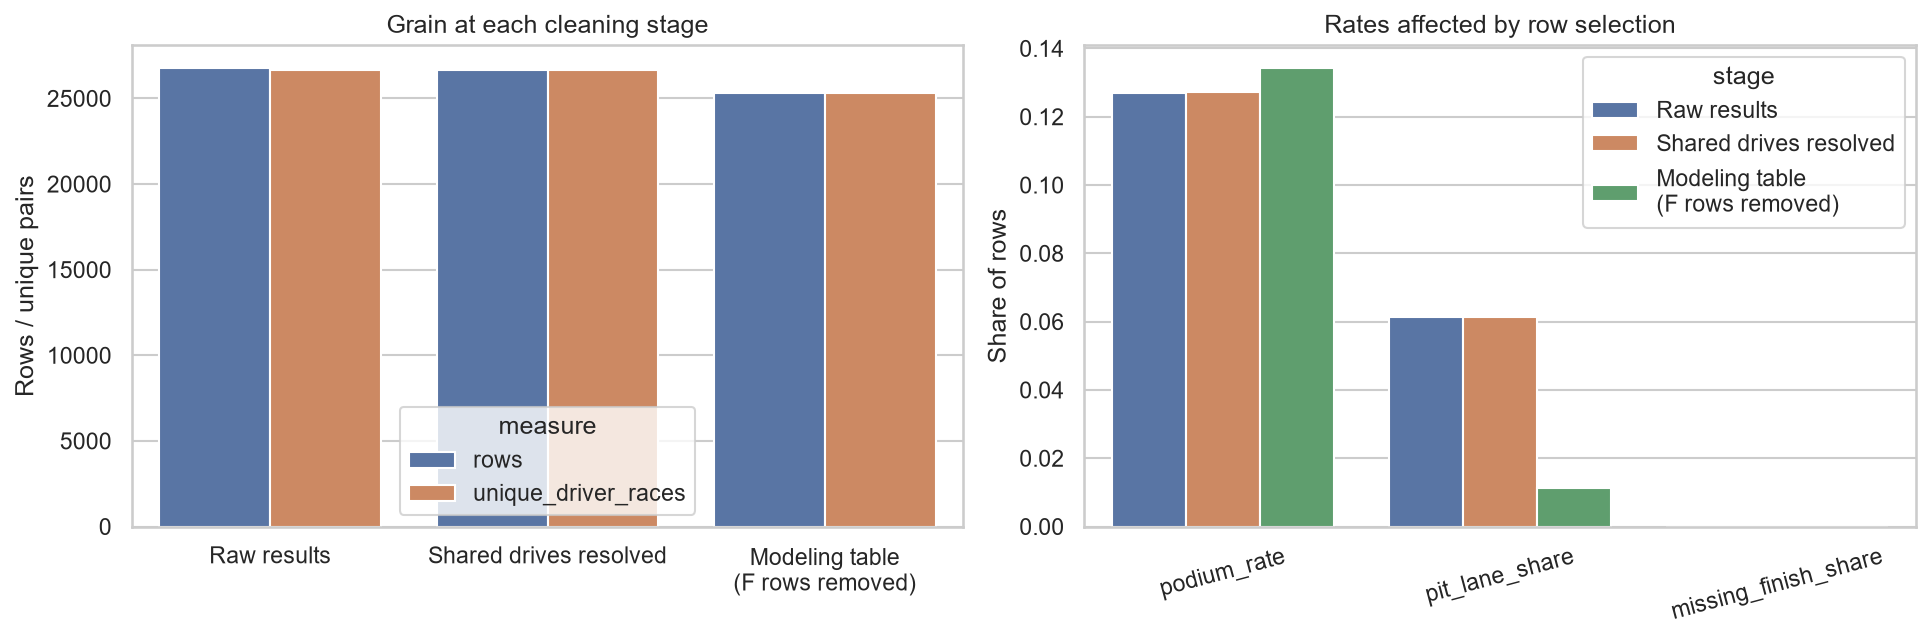

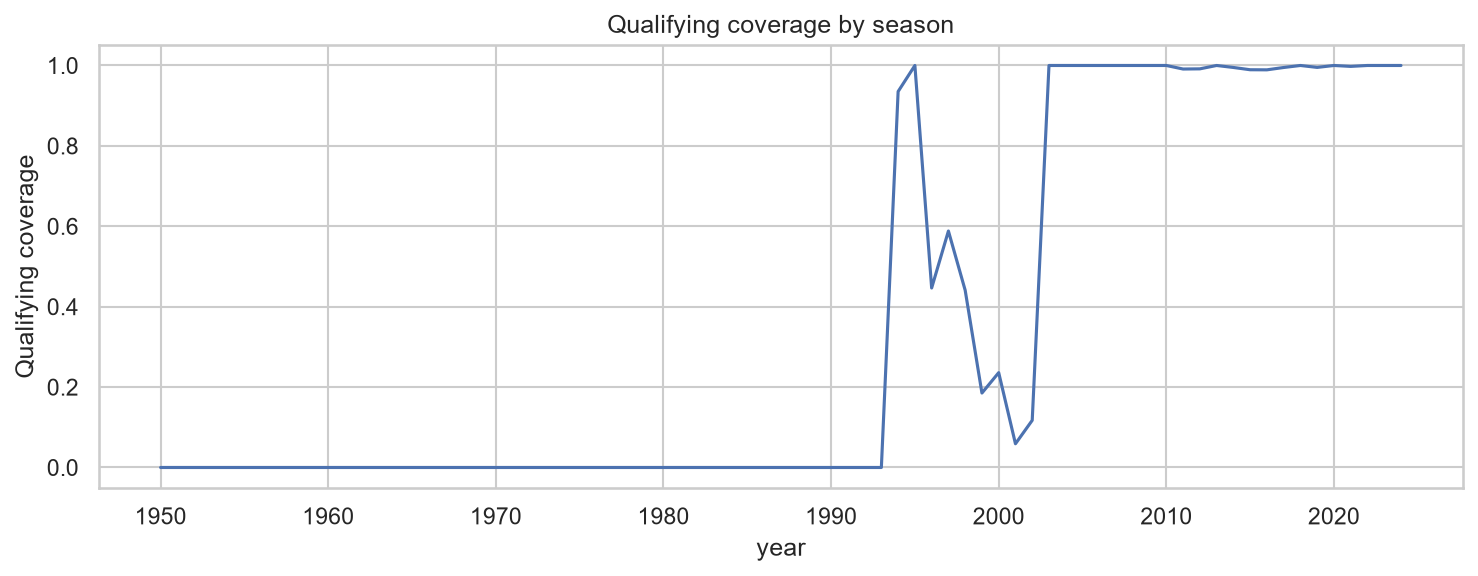

In [9]:
display(results["pk_audit"])
display(results["fk_audit"])
display(results["summary"]["diagnostics"])
display(results["cleaning_eda"])
display(Image(filename=str(OUT / "figures" / "cleaning_before_after.png")))
display(Image(filename=str(OUT / "figures" / "qualifying_coverage.png")))

Cleaning has two steps. The first fixes the grain: resolving 85 shared-drive groups removes 91 rows and leaves exactly one row per `(raceId, driverId)`, without moving the target (12.69% to 12.73%) or the median grid (12). The second step removes the 1,366 rows of drivers who did not enter the race (section 8.1). None of them is a podium, so the podium rate rises to 13.42% by arithmetic alone, and the grid-0 share falls from 6.1% to 1.1%. Qualifying coverage is sparse in older seasons, so we retain an explicit missingness flag and use final grid as the historically broader pre-race signal rather than discarding early history.

### 8.1 Who has grid 0? Drivers who did not enter, withdrawals, and the pit-lane flag

In [10]:
display(results["non_starters"].round(3))
display(results["non_starter_experiment"].round(4))

,group,treatment,rows,share_of_rows,grid_zero_share,podium_rate,first_year,last_year,rows_in_training,rows_in_validation,rows_in_test,main_statuses
0,regular grid start,kept,24880,0.933,0.000,0.136,1950,2024,22806,759,1315,Finished (7652); +1 Lap (4009); Engine (1987)
1,grid 0 but raced (pit-lane or exceptional start),kept,87,0.003,1.000,0.000,1981,2024,34,16,37,+1 Lap (27); Finished (22); +2 Laps (7)
2,W: withdrew,kept (the code is only known after the race),335,0.013,0.603,0.000,1950,2024,323,5,7,Withdrew (227); Accident (29); Engine (19)
3,"F: did not qualify, prequalify, or pass 107%",removed before features (known before the race),1366,0.051,0.985,0.000,1952,2012,1366,0,0,Did not qualify (1024); Did not prequalify (33...


,variant,train_rows,train_podium_rate,train_pit_lane_share,train_field_size,model,validation_PR-AUC,validation_ROC-AUC,PR-AUC_change_vs_used
0,drop F rows before features (used),23163,0.1327,0.0100,23.2477,Logistic regression,0.7301,0.9257,0.0000
1,drop F rows before features (used),23163,0.1327,0.0100,23.2477,Shallow neural network,0.7166,0.9215,0.0000
2,keep F rows in the history and in training,24529,0.1253,0.0643,25.0554,Logistic regression,0.7296,0.9256,-0.0005
3,keep F rows in the history and in training,24529,0.1253,0.0643,25.0554,Shallow neural network,0.7311,0.9292,0.0144
4,"keep F rows in the history, drop them from tra...",23163,0.1327,0.0100,24.6917,Logistic regression,0.7300,0.9256,-0.0001
5,"keep F rows in the history, drop them from tra...",23163,0.1327,0.0100,24.6917,Shallow neural network,0.7292,0.9255,0.0126
6,also drop W rows from training (not allowed),22840,0.1346,0.0015,24.6907,Logistic regression,0.7301,0.9257,0.0000
7,also drop W rows from training (not allowed),22840,0.1346,0.0015,24.6907,Shallow neural network,0.7349,0.9253,0.0182


**What the audit shows.** Before the `F` rows are removed, 6.1% of rows have grid 0, and the flag name `pit_lane_start` makes them sound like pit-lane starts. They are mostly not. Of the 1,635 grid-0 rows, 1,346 are drivers who never raced (positionText `F`: did not qualify, did not prequalify, or failed the 107% rule), 202 are withdrawals, and only 87 are real pit-lane or exceptional starts. All 1,366 `F` rows are in 1952-2012, all are in training, and none finished on the podium. Validation and test contain no `F` rows.

**Decision: remove the `F` rows, keep everything else (instructor ruling).** The instructor ruled that `F` rows are known before the race starts and may be removed, and that withdrawals (`W`) may not, because that code is only known after the race. A driver who did not qualify did not enter the race, so the row does not belong in a table of one driver entering one race. We remove the `F` rows *before* any feature is built. A skipped weekend therefore no longer counts as a race in `driver_podium_rate_5` or `driver_races_before`, and it no longer inflates `field_size` (training mean 25.06 with them, 23.25 without).

**Evidence that the choice is safe.** The experiment scores four variants on the same 2020-2021 validation rows. Keeping the `F` rows instead changes validation PR-AUC by -0.0005 for logistic regression and +0.0144 for the network. Keeping them in the history but dropping them from the training rows only changes it by -0.0001 and +0.0126. Logistic regression, which has no random seed, moves by at most 0.0005. The network moves by up to 0.0144, but a single network seed can sit 0.021 away from its own three-seed average (section 10.3), so the network cannot separate these options. The choice rests on the ruling and on what a row means, not on a score. Removing the `W` rows as well, which the ruling does not allow, would change the network by +0.0182.

**What changes.** `pit_lane_start` now marks 289 rows: 202 withdrawals with grid 0 and 87 drivers who raced from the pit lane or an exceptional start. It is no longer a did-not-qualify marker, but it is still not a pure pit-lane flag.

## 9. Answers to the three data-engineering questions


front_row_circuits


,era,circuit_name,mean,count
23,1950-2013,Circuit de Nevers Magny-Cours,0.805556,36
37,1950-2013,Istanbul Park,0.785714,14
30,1950-2013,Dijon-Prenois,0.750000,12
16,1950-2013,Circuit Bremgarten,0.700000,10
60,1950-2013,Sepang International Circuit,0.700000,30
63,1950-2013,Suzuka Circuit,0.700000,50
35,1950-2013,Hungaroring,0.678571,56
12,1950-2013,Bahrain International Circuit,0.666667,18
11,1950-2013,Autódromo do Estoril,0.653846,26
21,1950-2013,Circuit de Barcelona-Catalunya,0.652174,46



home_effect


,grid_band,home_race,mean,count
0,1-3,False,0.556536,3060
1,1-3,True,0.549242,264
2,4-6,False,0.263263,3016
3,4-6,True,0.246154,260
4,7-10,False,0.095489,3990
5,7-10,True,0.087855,387
6,11-15,False,0.030813,4933
7,11-15,True,0.034115,469
8,16+,False,0.007550,6887
9,16+,True,0.007503,933



mechanical_retirements


,era,constructor_name,mean,sum,count
4,2014-2021,Caterham,0.235294,8,34
8,2014-2021,Lotus F1,0.200000,15,75
17,2014-2021,Toro Rosso,0.165289,40,242
15,2014-2021,Renault,0.145000,29,200
11,2014-2021,McLaren,0.144654,46,318
16,2014-2021,Sauber,0.115000,23,200
14,2014-2021,Red Bull,0.112853,36,319
13,2014-2021,Racing Point,0.105263,8,76
1,2014-2021,AlphaTauri,0.102564,8,78
10,2014-2021,Marussia,0.096774,3,31


Statuses counted as mechanical:


['Alternator',
 'Battery',
 'Brake duct',
 'Brakes',
 'Clutch',
 'Cooling system',
 'Differential',
 'Driveshaft',
 'Drivetrain',
 'ERS',
 'Electrical',
 'Electronics',
 'Engine',
 'Engine fire',
 'Engine misfire',
 'Exhaust',
 'Fire',
 'Front wing',
 'Fuel leak',
 'Fuel pressure',
 'Fuel pump',
 'Fuel system',
 'Gearbox',
 'Hydraulics',
 'Mechanical',
 'Oil leak',
 'Oil pressure',
 'Overheating',
 'Power Unit',
 'Power loss',
 'Puncture',
 'Radiator',
 'Rear wing',
 'Safety belt',
 'Spark plugs',
 'Steering',
 'Suspension',
 'Technical',
 'Throttle',
 'Transmission',
 'Turbo',
 'Tyre',
 'Tyre puncture',
 'Undertray',
 'Vibrations',
 'Water leak',
 'Water pressure',
 'Water pump',
 'Wheel',
 'Wheel bearing',
 'Wheel nut']

Statuses excluded as non-starts:


['Did not prequalify',
 'Did not qualify',
 'Did not start',
 'Excluded',
 'Withdrew']

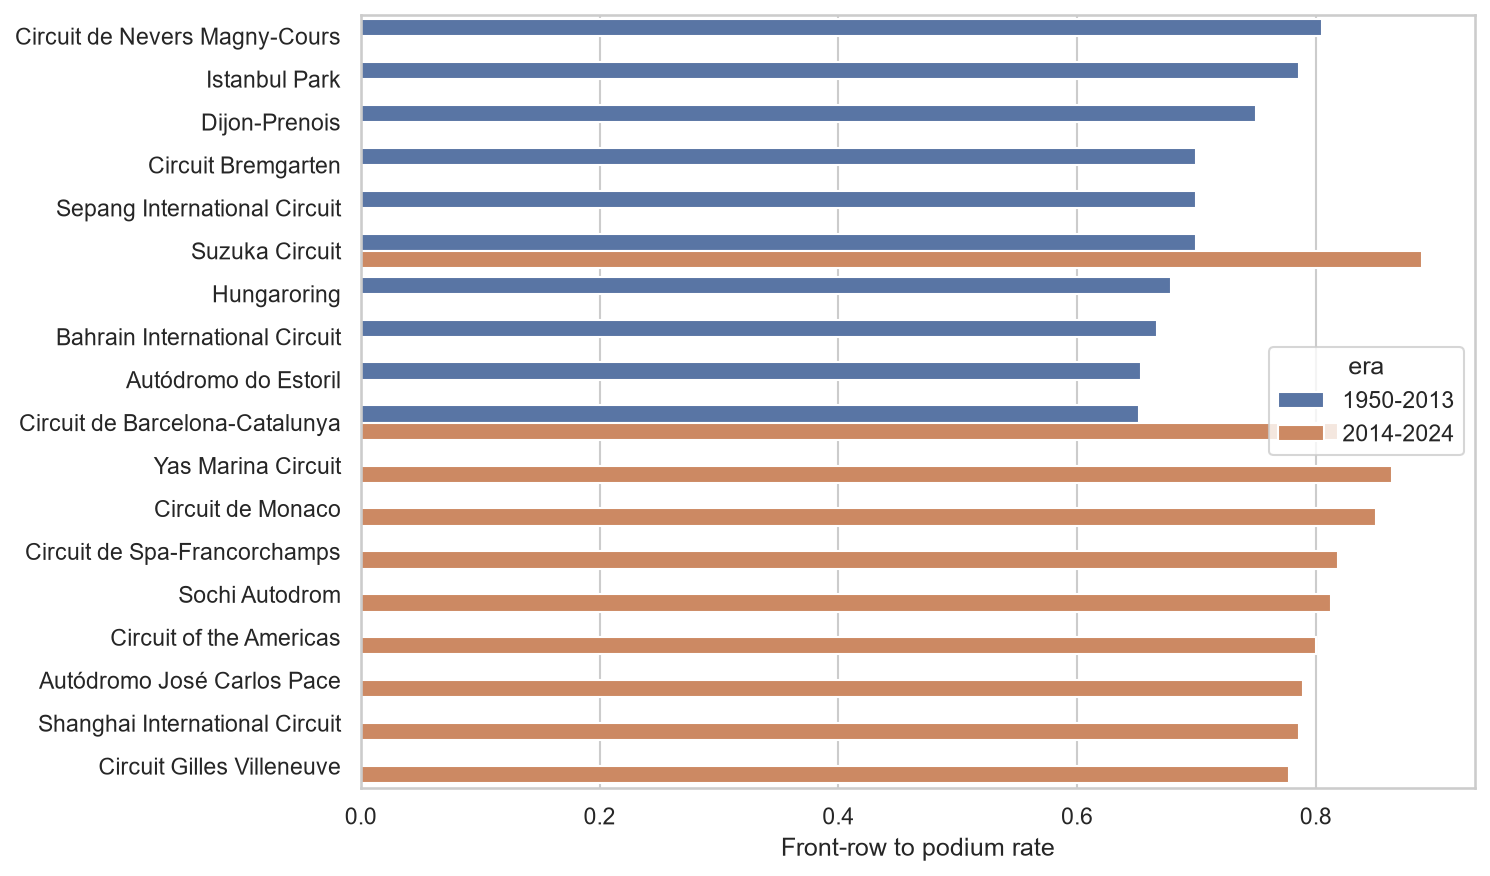

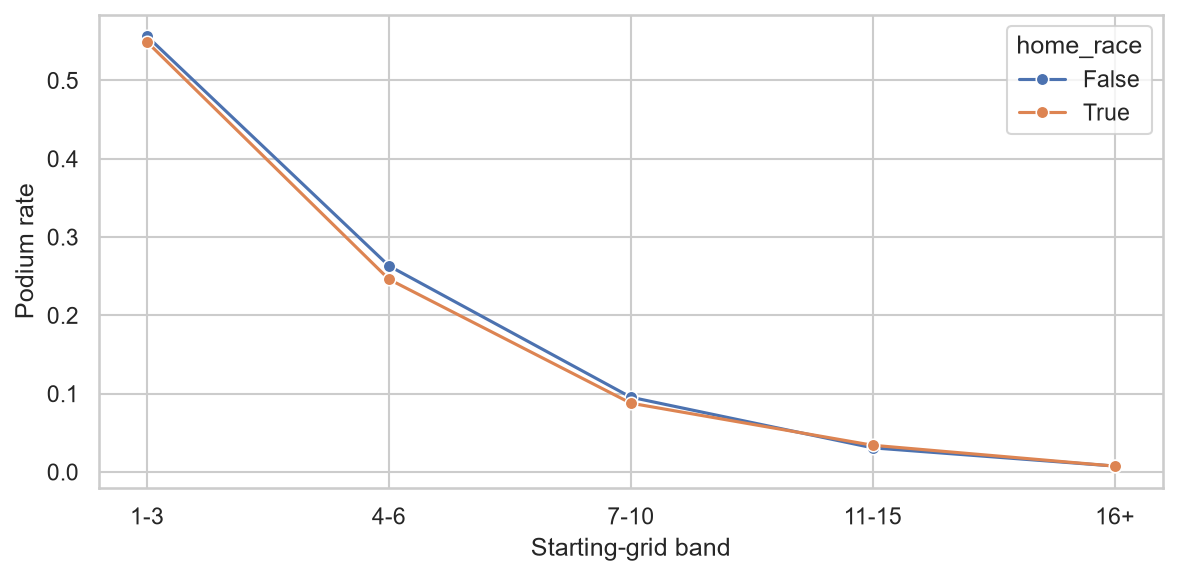

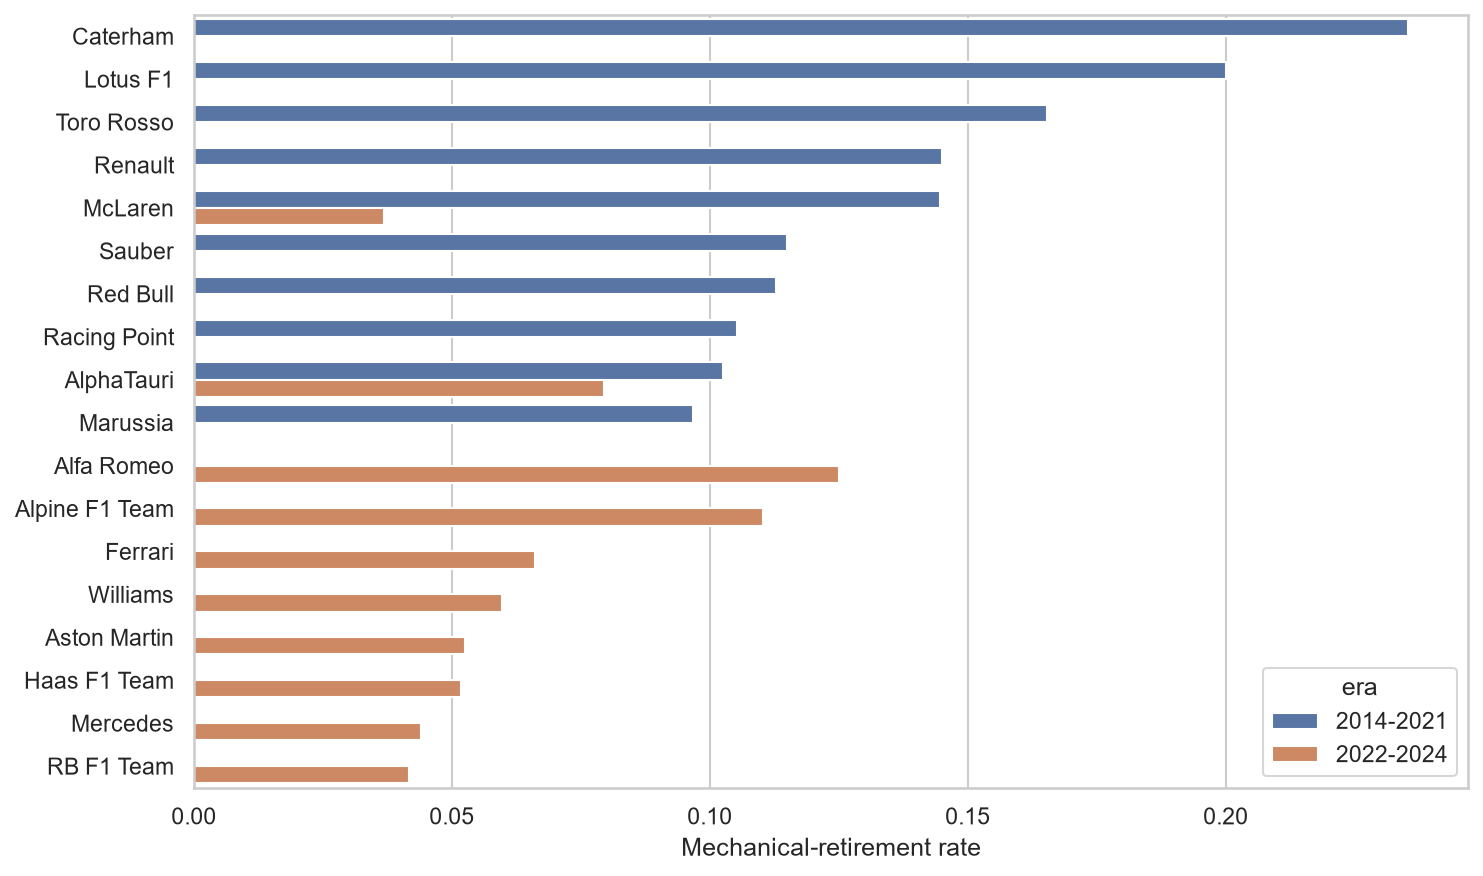

In [11]:
for key, table in results["answers"].items():
    print(f"\n{key}")
    display(table.groupby("era").head(10) if "era" in table else table)

print("Statuses counted as mechanical:")
display(results["summary"]["mechanical_statuses"])
print("Statuses excluded as non-starts:")
display(results["summary"]["non_start_statuses"])

for figure in ["front_row_conversion", "home_effect", "mechanical_retirements"]:
    display(Image(filename=str(OUT / "figures" / f"{figure}.png")))

**Front-row conversion.** Rankings are separated at the 2014 hybrid-era boundary and require at least ten front-row starts per circuit-era. Final grid positions 1-2 define the front row because penalties can make qualifying order differ from the actual start.

**Home-country effect.** Home and away rates are compared inside the same grid bands. This controls the dominant starting-position pattern transparently, but the result remains descriptive rather than causal.

**Mechanical retirements.** Rates use recorded race starters as the denominator and documented component-status labels as the numerator, with at least twenty starts per constructor-era. Ambiguous status coding remains a limitation. Engine fire and engine misfire are counted as mechanical because they are engine failures; heat shield fire is not counted, following TA feedback. None of these statuses occur in 2014-2024, so this choice does not change the rates.

## 10. Leakage-safe features

In [12]:
display(FEATURE_GROUPS)

{'grid': ['grid_position', 'pit_lane_start', 'front_row', 'field_size'],
 'qualifying': ['qualifying_position',
  'qualifying_time_seconds',
  'qualifying_missing'],
 'form': ['driver_podium_rate_5',
  'constructor_podium_rate_5',
  'driver_races_before'],
 'standings': ['driver_points_before',
  'driver_rank_before',
  'constructor_points_before',
  'constructor_rank_before'],
 'context': ['driver_age', 'year']}

Every selected feature is known after qualifying and before the start. Driver form shifts before rolling, constructor outcomes are aggregated by race before shifting, and standings attach only to the following race. Current-race position, points, status, laps, pit stops, and fastest-lap information never enter `FEATURES`.

### Standings before the first race of a season

Before a driver's or team's first race of a season there are no standings yet. Earlier these cells were empty, and the median imputer filled them with about 3 points and rank 13, which invents points nobody has scored. We now set them to 0 points and rank 0 when the features are built, so the imputer no longer touches the standings columns.

In [13]:
mt = results["modeling_table"]
cols = ["driver_points_before", "driver_rank_before", "constructor_points_before", "constructor_rank_before"]
r1 = mt[mt["round"] == 1]
print("Round-1 driver points values:", r1["driver_points_before"].unique())
print("Round-1 driver rank values:", r1["driver_rank_before"].unique())
print("Empty standings cells left (should be 0):", mt[cols].isna().sum().sum())

Round-1 driver points values: [0.]
Round-1 driver rank values: [0.]
Empty standings cells left (should be 0): 0


**Result:** Every round-1 row now has 0 points and rank 0, and no standings cell is left empty. We also tested adding flags to mark these rows, since rank 0 could look better than first place. They gave no validation gain (logistic regression unchanged, forest and network lower), so no flags were added.

### 10.1 Sprint races: a leakage judgement call

In [14]:
display(results["sprint_check"].round(3))

,season,sprint_races,driver_rows,split,sprint_ends_before_race_share,days_before_race,grid_vs_sprint_finish,grid_vs_qualifying,sprint_rows_in_training
0,2021,3,60,validation,1.0,1.0,0.886,0.826,0
1,2022,3,60,test,1.0,1.0,0.989,0.723,0
2,2023,6,120,test,1.0,1.0,0.619,0.987,0
3,2024,6,120,test,1.0,1.0,0.542,0.963,0


**Question.** Does the sprint create a leakage problem? A sprint is a separate short race on the same weekend, with its own result in `sprint_results`.

**Timing.** Every sprint ends one day before the main race (`sprint_ends_before_race_share` is 1.0 in every season), so a sprint result is known before the lights go out. It is not post-race information, and using it would not break the cutoff by time.

**Why we still do not use it.** First, sprints exist only from 2021, so there are 0 sprint rows in training (1950-2019). A sprint feature would be empty for every row the model learns from. Second, in 2021-2022 the sprint set the main-race grid: the rank correlation between grid and sprint finish is 0.89 and 0.99, against 0.83 and 0.72 with qualifying. The grid features already carry that information. In 2023-2024 the sprint stopped setting the grid (grid follows qualifying at 0.99 and 0.96) and adds a separate signal for only 12 weekends. We therefore exclude sprint columns from `FEATURES` by design, not because they leak.

**The real hazard.** Sprint finishing position and sprint points sit under the same `raceId` as the main race. Joining them by `raceId` would look harmless, but their meaning is a different race's result. Standings are already moved to the following race, so sprint points reach the features only through the previous round, never the current one.

### 10.2 Exploratory evidence for every individual feature

,group,feature,missing_share_train,podium_rate_when_missing,podium_rate_lowest_bin,podium_rate_highest_bin,auc_train,auc_validation,direction,signal_strength,same_direction_in_validation
0,grid,grid_position,0.010,0.000,0.471,0.005,0.119,0.093,"lower value, more podiums",0.762,True
1,grid,pit_lane_start,0.000,NaN,0.134,0.000,0.494,0.487,"lower value, more podiums",0.012,True
2,grid,front_row,0.000,NaN,0.089,0.585,0.672,0.733,"higher value, more podiums",0.344,True
3,grid,field_size,0.000,NaN,0.161,0.111,0.454,0.500,"lower value, more podiums",0.092,False
4,qualifying,qualifying_position,0.640,0.129,0.525,0.007,0.095,0.081,"lower value, more podiums",0.811,True
5,qualifying,qualifying_time_seconds,0.645,0.129,0.171,0.108,0.451,0.458,"lower value, more podiums",0.097,True
6,qualifying,qualifying_missing,0.000,NaN,0.139,0.129,0.490,0.499,"lower value, more podiums",0.020,True
7,form,driver_podium_rate_5,0.035,0.028,0.058,0.425,0.810,0.836,"higher value, more podiums",0.619,True
8,form,constructor_podium_rate_5,0.014,0.050,0.037,0.403,0.826,0.854,"higher value, more podiums",0.652,True
9,form,driver_races_before,0.000,NaN,0.047,0.223,0.662,0.702,"higher value, more podiums",0.324,True


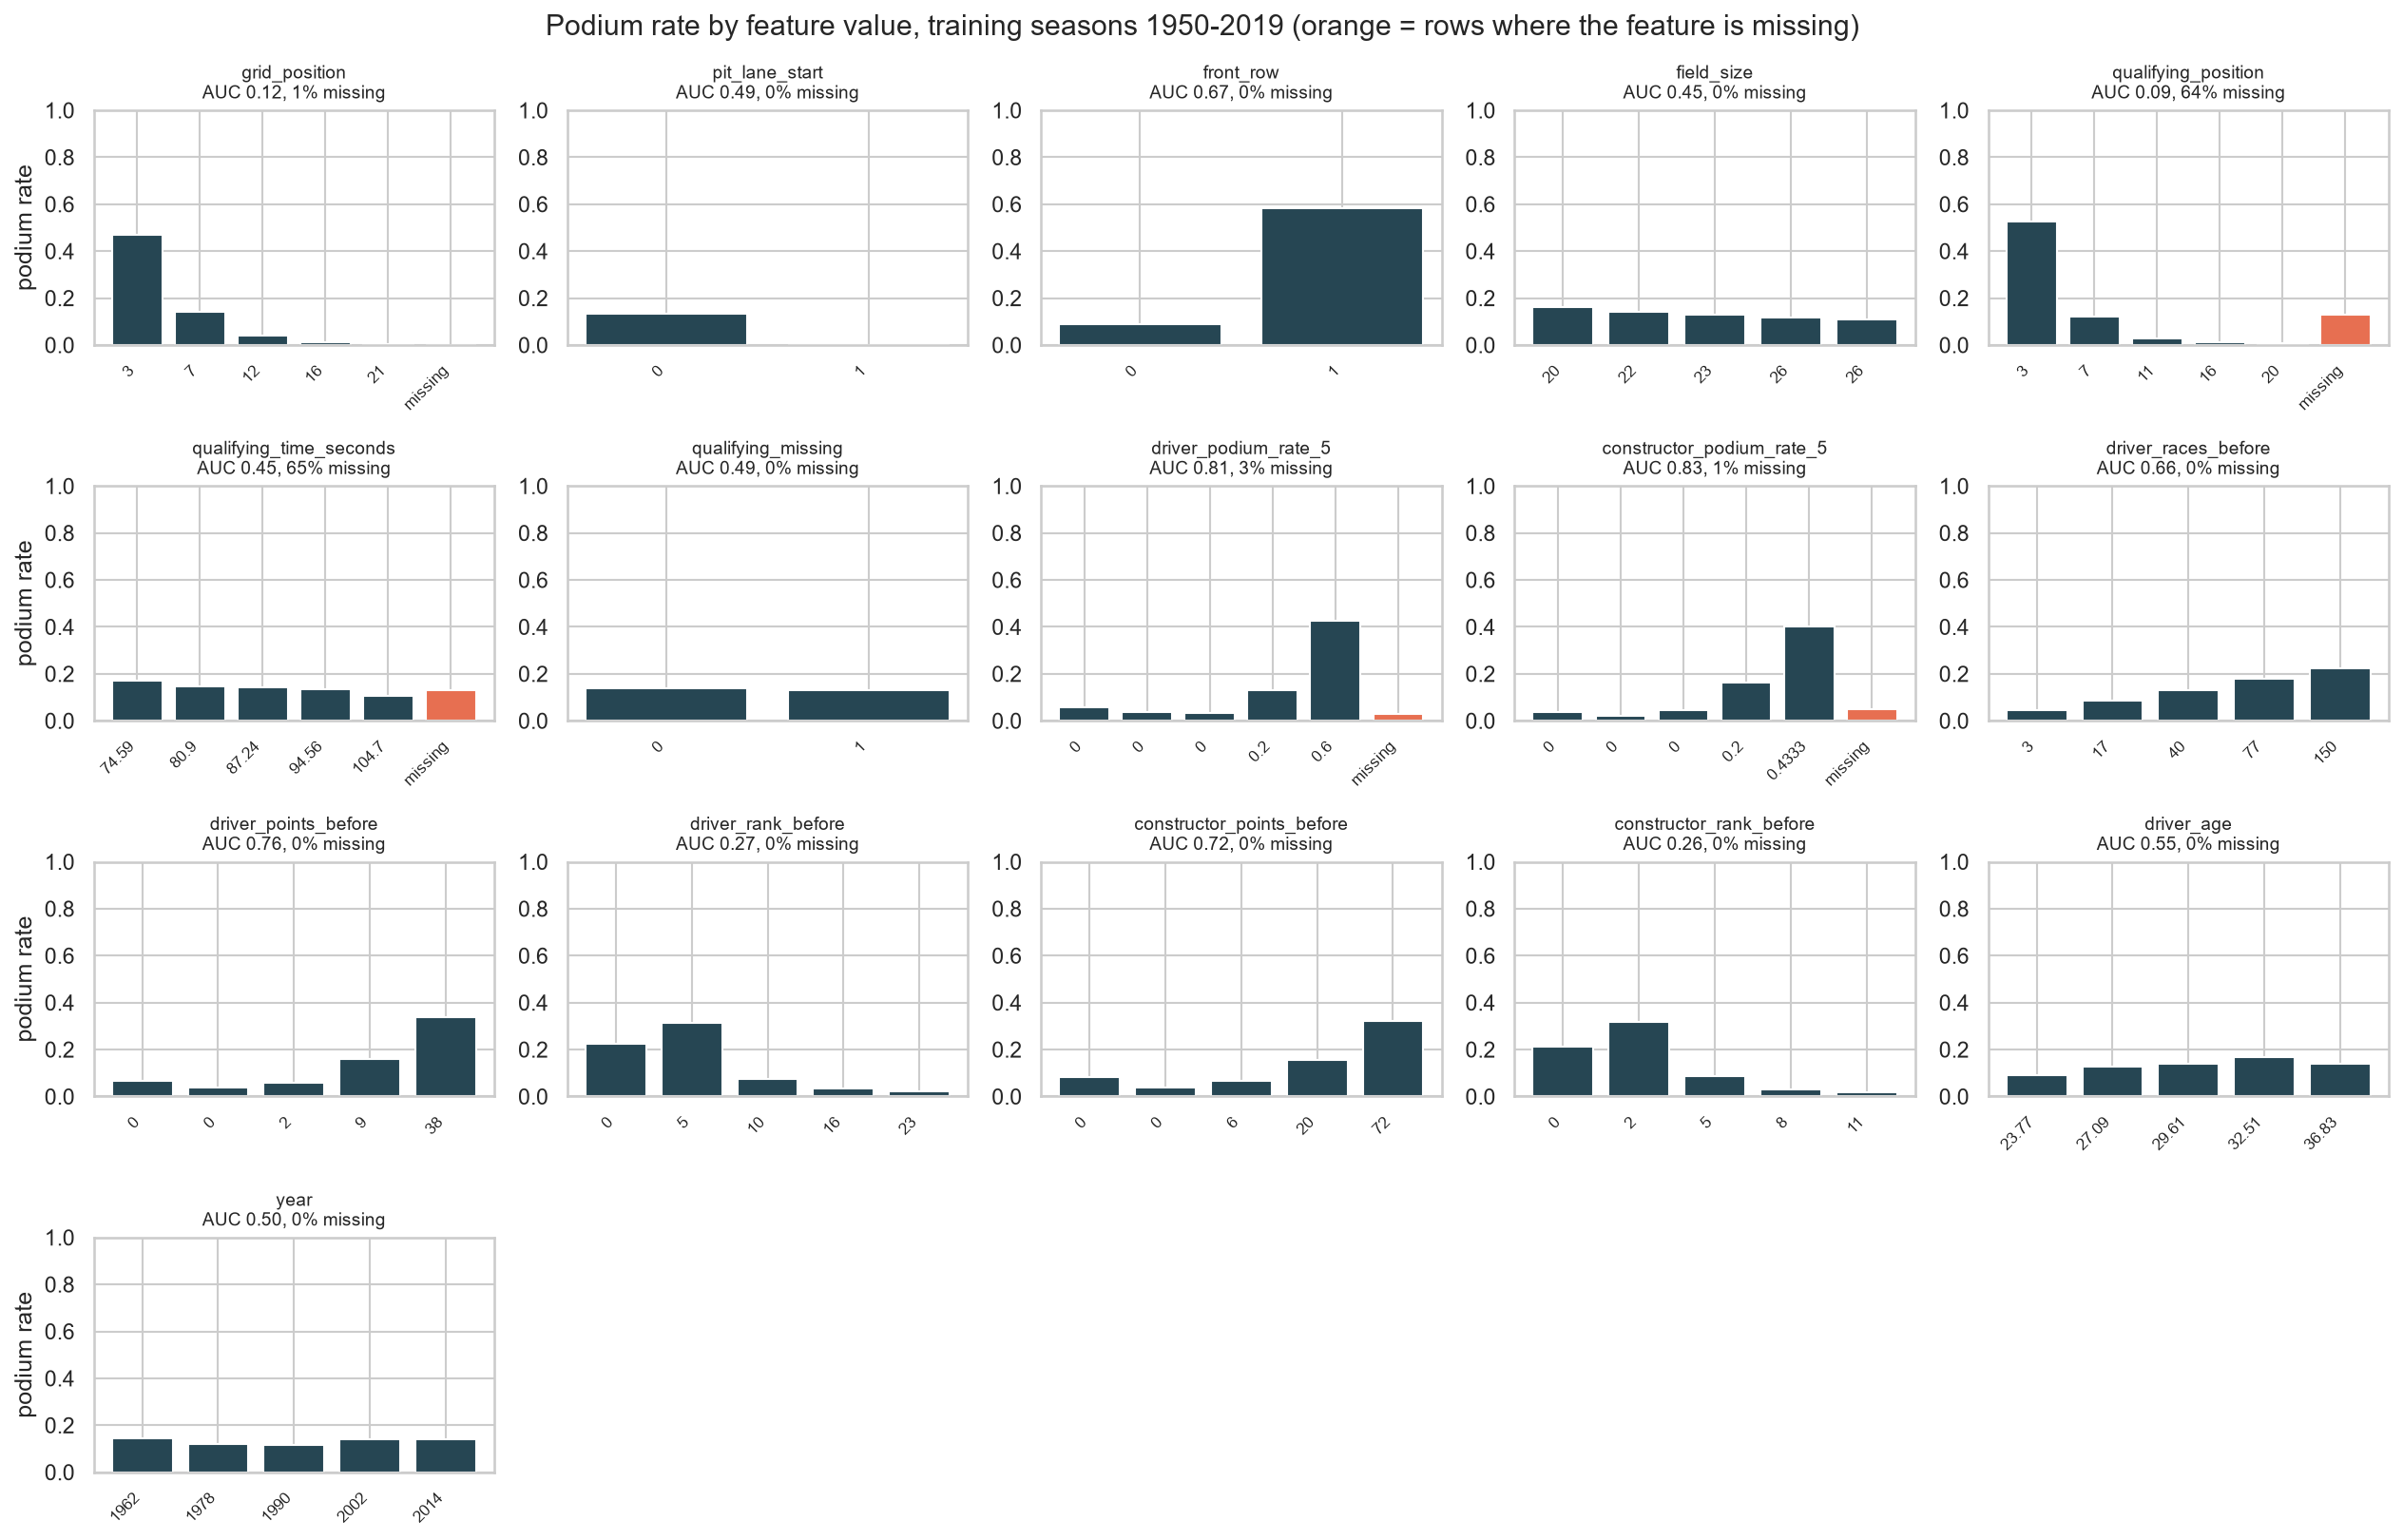

In [15]:
display(results["feature_eda"].drop(columns=["bins"]).round(3))
display(Image(filename=str(OUT / "figures" / "feature_eda.png")))

The table and figure use **training seasons only**. For each of the 16 features they show the share of missing cells, the podium rate in its lowest and highest bin, and a one-feature ROC-AUC (above 0.5 means a higher value goes with more podiums, below 0.5 the reverse). The same AUC on validation checks that the pattern still holds in later seasons. Missing cells are left out of the AUC and the bins, and the orange bar in the figure shows the podium rate of the rows where the feature is missing.

**Strong single signals.** Position features carry the most: `qualifying_position` (AUC 0.09, so lower is better, measured on the 36% of rows that have it) and `grid_position` (0.12). The podium rate falls from 47% (grid) and 52% (qualifying) in the best bin to 0.5% and 0.7% in the worst. The standings ranks (0.27 and 0.26), form rates (0.81 and 0.83), and points (0.76 and 0.72) are next, and `front_row` (0.67) and `driver_races_before` (0.66) are clear but smaller. All of these keep the same direction on validation (for example 0.09 for grid and 0.84 and 0.85 for form).

**Weak single signals, kept for a different reason.** `field_size` (0.45), `driver_age` (0.55), `qualifying_time_seconds` (0.45), `pit_lane_start` (0.49), and `qualifying_missing` (0.49) are close to 0.5 on their own. The qualifying time is not comparable across circuits and eras, so a raw time says little without the rest of the row. The two flags are indicators: removing `qualifying_missing` changes validation PR-AUC only slightly (section 13.1), but the flag records which rows were imputed, and rows with no grid position (withdrawals and pit-lane starts) never podium, while rows with no qualifying record podium at about the average rate (12.9% against 13.3%). `year` (0.50) has essentially no single-feature signal, and `field_size` and `year` are flat or constant on validation (every 2020-2021 race has 20 starters). The ablation shows the whole context group adds the least of the five (0.001 PR-AUC). Section 10.3 tests the two calendar features one at a time: `year` is kept and `round` was removed.

**What this evidence does and does not show.** A one-feature AUC ignores the other 15 features, so a feature that looks weak here can still help in combination, and a strong feature can add little once the grid is present (the ablation shows qualifying adds only 0.006 on top of the grid). The AUCs describe association in past races and are not causal effects.

### 10.3 Calendar features: keep `year`, remove `round`

In [16]:
context = results["context_experiment"]
display(context.round(4))
display(context.pivot_table(index="variant", columns="model", values="PR-AUC_change_vs_used", sort=False).round(4))

,variant,model,features,validation_PR-AUC,validation_PR-AUC_std,seed_42_PR-AUC,PR-AUC_change_vs_used
0,used (no round),Logistic regression,16,0.7301,0.0000,0.7301,0.0000
1,used (no round),Random forest,16,0.7125,0.0000,0.7125,0.0000
2,used (no round),Shallow neural network,16,0.7228,0.0052,0.7166,0.0000
3,put round back,Logistic regression,17,0.7293,0.0000,0.7293,-0.0008
4,put round back,Random forest,17,0.7161,0.0000,0.7161,0.0037
5,put round back,Shallow neural network,17,0.7232,0.0170,0.7443,0.0003
6,also remove year,Logistic regression,15,0.7307,0.0000,0.7307,0.0006
7,also remove year,Random forest,15,0.7080,0.0000,0.7080,-0.0045
8,also remove year,Shallow neural network,15,0.7017,0.0157,0.7108,-0.0212
9,"round back, year removed",Logistic regression,16,0.7289,0.0000,0.7289,-0.0012


model,Logistic regression,Random forest,Shallow neural network
variant,,,
used (no round),0.0000,0.0000,0.0000
put round back,-0.0008,0.0037,0.0003
also remove year,0.0006,-0.0045,-0.0212
"round back, year removed",-0.0012,-0.0045,-0.0360


**Question.** `year` and `round` were added as context: the era and the point in the season. On their own neither separates podiums from the rest (single-feature AUC 0.50 for `year`, and about 0.50 for `round` in the earlier run), so we tested each one inside the full models. Every variant is trained on 1950-2019 and scored on 2020-2021 only. The network is averaged over three seeds, the same as the settings search in section 14.1.

**`round` adds nothing, so we removed it.** Putting `round` back changes validation PR-AUC by -0.0008 for logistic regression, which has no random seed, by +0.0037 for the forest, and by +0.0003 for the network, far inside the noise of a three-seed average (about 0.010). None of these comes close to a real effect such as removing `year` (-0.0212 for the network), and they do not even agree in direction. The information is also already in the standings: points and rank build up race by race, so they tell the model how far into the season it is. Finally, `round` does not mean the same thing across eras. A season had about 8 races in the 1950s and 24 in 2024, so round 8 was a season finale then and an early race now. With no measurable gain and an unstable meaning, the simpler model wins.

**`year` helps, so we kept it.** Removing `year` changes the score by +0.0006 for logistic regression, -0.0045 for the forest and -0.0212 for the network. The network loses the most of the three models, about 2 times the noise of a three-seed average (about 0.010, the seed spread divided by the square root of 3). On its own `year` says nothing, but together with grid and form it lets the nonlinear models adjust for the era: larger fields, worse reliability, and missing qualifying in the older seasons. The same test inside the old 17-feature model, with `round` still there, gives -0.0004, -0.0082 and -0.0363, so `year` helps the nonlinear models with or without `round`. That old model without `year` is also unstable: its network seed spread is 0.045. One caveat: the test seasons (2022-2024) lie outside the training years (1950-2019), so the models must extrapolate `year`. A tree cannot extrapolate, so the forest treats 2022 like 2019.

**Why one seed is not enough.** The main results table trains each model once, with seed 42. With `round`, the network's seed-42 score was 0.7443, 0.021 above its own three-seed average of 0.7232. Without `round`, seed 42 scores 0.7166 and the average is 0.7228. The average barely moved, but the single seed fell, and that alone changes which model looks best in section 14. This is why we read single-seed network differences of about 0.021 as noise throughout the notebook.

### 10.4 Team renames and reused constructor ids

In [17]:
display(results["constructor_history"])

,constructor_name,constructorId,year,case,rows_in_first_5_races,podiums,max_constructor_form,split
0,Manor Marussia,209,2015,new id: form starts empty,10,0,0.0,train
1,Haas F1 Team,210,2016,new id: form starts empty,10,0,0.0,train
2,Renault,4,2016,reused id: form comes from 2011,10,0,0.0,train
3,Alfa Romeo,51,2019,reused id: form comes from 1985,10,0,0.0,train
4,Racing Point,211,2019,new id: form starts empty,10,0,0.0,train
5,AlphaTauri,213,2020,new id: form starts empty,10,0,0.0,validation
6,Alpine F1 Team,214,2021,new id: form starts empty,10,0,0.0,validation
7,Aston Martin,117,2021,reused id: form comes from 1960,10,0,0.0,validation
8,RB F1 Team,215,2024,new id: form starts empty,10,0,0.0,test
9,Sauber,15,2024,reused id: form comes from 2018,10,0,0.0,test


**What happens.** Constructor form (`constructor_podium_rate_5`, the team's podium rate over its last five races) is computed per `constructorId`. When a team is renamed, the dataset usually gives it a new id, so its form starts empty: Toro Rosso became AlphaTauri in 2020, Renault became Alpine in 2021, and AlphaTauri became RB in 2024. The opposite also happens. Some old ids are used again years later, so a team inherits an earlier history: Aston Martin in 2021 reuses the id of the unrelated 1959-1960 Aston Martin, and Sauber in 2024 continues the Sauber id last used in 2018 (the same team, which raced as Alfa Romeo in between). The table lists every such team-season since 2014.

**How much it matters.** Only constructor form is affected. Standings restart every season, so a rename never carries over into them, and driver form follows the driver from team to team. Because the form window is five races, only the first five races of each listed season are touched: 30 of 780 validation rows and 20 of 1,359 test rows. None of these rows is a podium, and their constructor form is 0 or empty. An empty value is filled with the training median, which is 0, so a reset team and a team with no recent podiums look the same to the model.

**Decision.** We keep the ids as they are in the data and document the reset. Linking renamed teams would need a judgement for every case: Toro Rosso to AlphaTauri was a rebrand of the same team, but Force India to Racing Point followed a sale out of administration, and a merged history would also join eras with different owners, budgets and engines. With 50 affected validation and test rows, no podiums among them, and a feature that is already 0 for them, a hand-made mapping would add assumptions for very little effect on the evaluation. The reset stays listed as a limitation in section 18.

## 11. Proper train / validation / test split

,split,years,first_race,last_race,rows,share_of_rows,races,drivers,starters_per_race,podiums,podium_rate,qualifying_missing
0,train,1950-2019,1950-05-13,2019-12-01,23163,0.915461,1018,800,22.753438,3074,0.132712,0.639598
1,validation,2020-2021,2020-07-05,2021-12-12,780,0.030828,39,28,20.000000,117,0.150000,0.001282
2,test,2022-2024,2022-03-20,2024-12-08,1359,0.053711,68,28,19.985294,204,0.150110,0.000000


,check,passed
0,every row assigned to exactly one split,True
1,no race shared by train and validation,True
2,no race shared by validation and test,True
3,no race shared by train and test,True
4,last training race before first validation race,True
5,last validation race before first test race,True
6,both classes present in every split,True


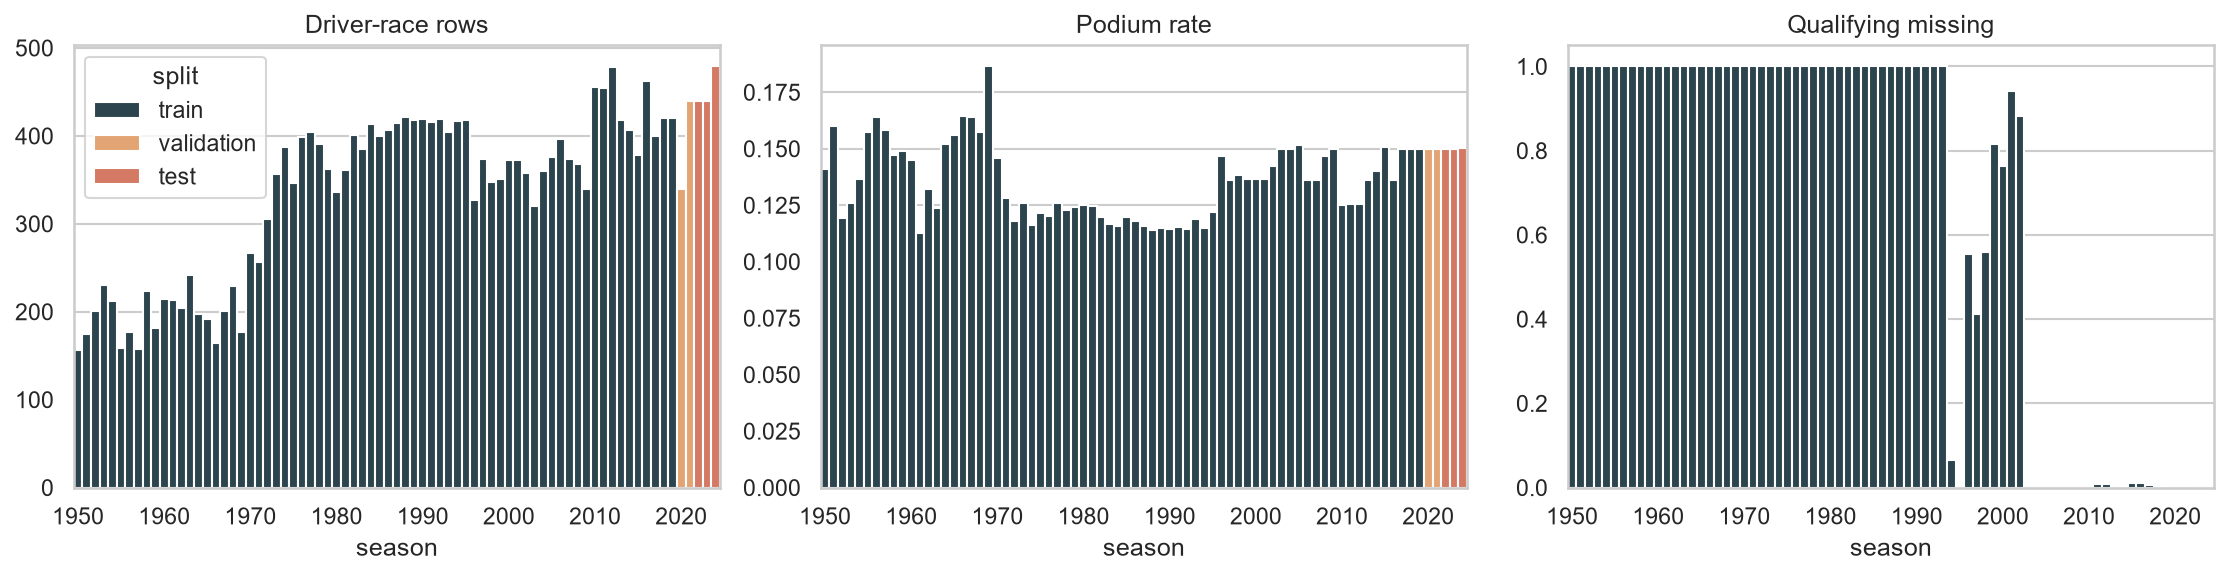

,strategy,train_rows,held_out_rows,held_out_years,held_out_podium_rate,held_out_races_also_in_train,held_out_rows_with_future_training,PR-AUC,ROC-AUC
0,chronological (used),23163,780,2020-2021,0.150000,0.0,0.000000,0.730083,0.925681
1,random races,24534,768,1952-2023,0.132812,0.0,1.000000,0.626675,0.919935
2,random rows,24522,780,1950-2024,0.110256,1.0,0.982051,0.587827,0.900509


In [18]:
display(results["split_summary"])
display(results["split_integrity"])
display(Image(filename=str(OUT / "figures" / "chronological_split.png")))
display(results["split_strategies"])

**Choice.** Training is 1950-2019, validation 2020-2021, and the unseen test set 2022-2024. The split is by season, so every race belongs to exactly one split and every training race happens before every validation race, which happens before every test race (all integrity checks pass). This matches deployment: on race morning the model only knows earlier seasons.

**Roles.** Training fits the imputer, scaler, and model weights. Validation is used for every decision: preprocessing variant and order, feature-group ablation, model choice, and the probability threshold. The test seasons are scored once, after those choices are frozen.

**Why not random.** The strategy experiment holds out the same number of rows three ways. A random-row split puts the teammates and rivals from the same race in training for almost every held-out row, and nearly all held-out rows have later seasons in training. That would let the model learn from the future and from the same race. A random-race split removes same-race leakage but still trains on later seasons. Random splits also mix every era into the held-out set, so their score answers a different question from "how well do we predict the next seasons?". Only the chronological split has zero same-race and zero future leakage.

**Shift between splits.** Training has far more missing qualifying and larger fields, so its podium rate is lower. That shift is real and is the reason for a separate recent validation period rather than validating on old seasons.

### 11.1 Is 2019 the right boundary? Other validation windows and uncertainty

In [19]:
display(results["split_windows"].round(4))
display(results["validation_uncertainty"].round(4))

,validation_window,train_years,train_rows,validation_rows,validation_races,validation_podium_rate,Logistic regression PR-AUC,Shallow neural network PR-AUC
0,2014-2015,1950-2013,20676,785,38,0.1452,0.7164,0.7142
1,2016-2017,1950-2015,21461,862,41,0.1427,0.7282,0.7396
2,2018-2019,1950-2017,22323,840,42,0.1500,0.6893,0.7255
3,2020-2021 (used),1950-2019,23163,780,39,0.1500,0.7301,0.7166


,comparison,validation_PR-AUC,ci_low_2.5%,ci_high_97.5%,races
0,Logistic regression,0.7301,0.6206,0.8378,39
1,Random forest,0.7125,0.5947,0.8299,39
2,Shallow neural network,0.7166,0.6045,0.8284,39
3,Random forest minus Logistic regression,-0.0176,-0.0553,0.0246,39
4,Shallow neural network minus Logistic regression,-0.0135,-0.0396,0.0147,39


The first table keeps the same two models and scores four validation windows, each training on all earlier seasons and each ending before the test seasons, so the test set is never used. The score depends on the window: logistic regression ranges from 0.689 to 0.730 PR-AUC and the network from 0.714 to 0.740. The 2020-2021 window we use ranks 1st of 4 for logistic regression and 3rd of 4 for the network. The score moves by a few hundredths depending on which two seasons are held out, so a validation score should not be read as the expected test score. The test seasons, which were never used for a decision, score lower for both models (0.702 and 0.716).

The second table bootstraps whole validation races. With only 39 races, each model's PR-AUC has a 95% interval about 0.2 wide (for example 0.62-0.84 for logistic regression). The difference between the network and logistic regression is -0.013 with an interval of -0.040 to +0.015, and for the forest it is -0.018 with an interval of -0.055 to +0.025. Both intervals include zero, so the data do not show that any model is better than the baseline. We keep the chronological split because it is the only one with no same-race or future leakage, but we report the model ranking as a tie within validation uncertainty.

## 12. Effect of feature engineering and preprocessing on distributions, ranges, and values

### 12.1 Feature-engineering steps

In [20]:
display(results["feature_engineering_effects"])

,column,rows,missing_share,zero_share,min,median,max,mean
0,grid (raw),25302,0.000000,0.011422,0.000,11.0000,34.00,11.723856
1,grid_position (0 -> missing),25302,0.011422,0.000000,1.000,12.0000,34.00,11.859313
2,pit_lane_start (grid == 0),25302,0.000000,0.988578,0.000,0.0000,1.00,0.011422
3,q1/q2/q3 text present,10494,0.000000,0.014866,0.000,1.0000,1.00,0.985134
4,best qualifying seconds (parsed),10494,0.014866,0.000000,53.377,86.6935,1002.64,87.945700
5,qualifying_time_seconds (joined),25302,0.591653,0.000000,53.377,86.6905,1002.64,87.943764
6,driver_podium_rate_5 (shifted),25302,0.032171,0.647103,0.000,0.0000,1.00,0.136866
7,driver_points_before (previous race),25302,0.000000,0.407557,0.000,3.0000,549.00,17.721973


The table compares each raw source column with the feature built from it (all 1950-2024 rows of the modeling table). Raw `grid` still contains 1.1% zeros (withdrawals and pit-lane or exceptional starts), which would sit numerically *ahead* of pole. In `grid_position` those zeros become missing, the minimum becomes 1, and the information moves to the binary `pit_lane_start` flag. Qualifying strings such as `1:23.456` become numeric seconds; the left join to every driver-race row then exposes the missing qualifying history of older seasons (59% of rows have no qualifying time). Shifted form is missing on a driver's first race, because no earlier result exists, and the imputer fills that gap in the next step. Previous-race standings have no earlier value before a driver's or team's first race of a season, but nothing has been scored yet, so they are set to 0 rather than imputed.

### 12.2 Imputation and scaling

,feature,missing_share,fill_value,raw_min,raw_max,raw_mean,raw_std,imputed_std,std_change_from_imputation,scaled_min,scaled_max,scaled_mean,scaled_std,validation_scaled_mean,test_scaled_mean
0,grid_position,0.010,12.000,1.000,34.000,12.002,6.897,6.862,-0.005,-1.603,3.206,-0.0,1.0,-0.235,-0.248
1,pit_lane_start,0.000,0.000,0.000,1.000,0.010,0.100,0.100,0.000,-0.101,9.942,0.0,1.0,0.118,0.195
2,front_row,0.000,0.000,0.000,1.000,0.088,0.283,0.283,0.000,-0.310,3.227,-0.0,1.0,0.044,0.041
3,field_size,0.000,23.000,10.000,42.000,23.248,3.415,3.415,0.000,-3.880,5.492,-0.0,1.0,-0.951,-0.955
4,qualifying_position,0.640,11.000,1.000,26.000,11.364,6.360,3.822,-0.399,-2.651,3.891,-0.0,1.0,-0.168,-0.167
5,qualifying_time_seconds,0.645,87.244,63.003,1002.640,88.783,15.761,9.415,-0.403,-2.633,97.172,-0.0,1.0,-0.454,-0.254
6,qualifying_missing,0.000,1.000,0.000,1.000,0.640,0.480,0.480,0.000,-1.332,0.751,0.0,1.0,-1.329,-1.332
7,driver_podium_rate_5,0.035,0.000,0.000,1.000,0.136,0.233,0.231,-0.012,-0.567,3.769,0.0,1.0,0.080,0.085
8,constructor_podium_rate_5,0.014,0.000,0.000,1.000,0.137,0.200,0.200,-0.004,-0.675,4.338,-0.0,1.0,0.053,0.078
9,driver_races_before,0.000,40.000,0.000,324.000,60.546,61.831,61.831,0.000,-0.979,4.261,0.0,1.0,0.979,1.387


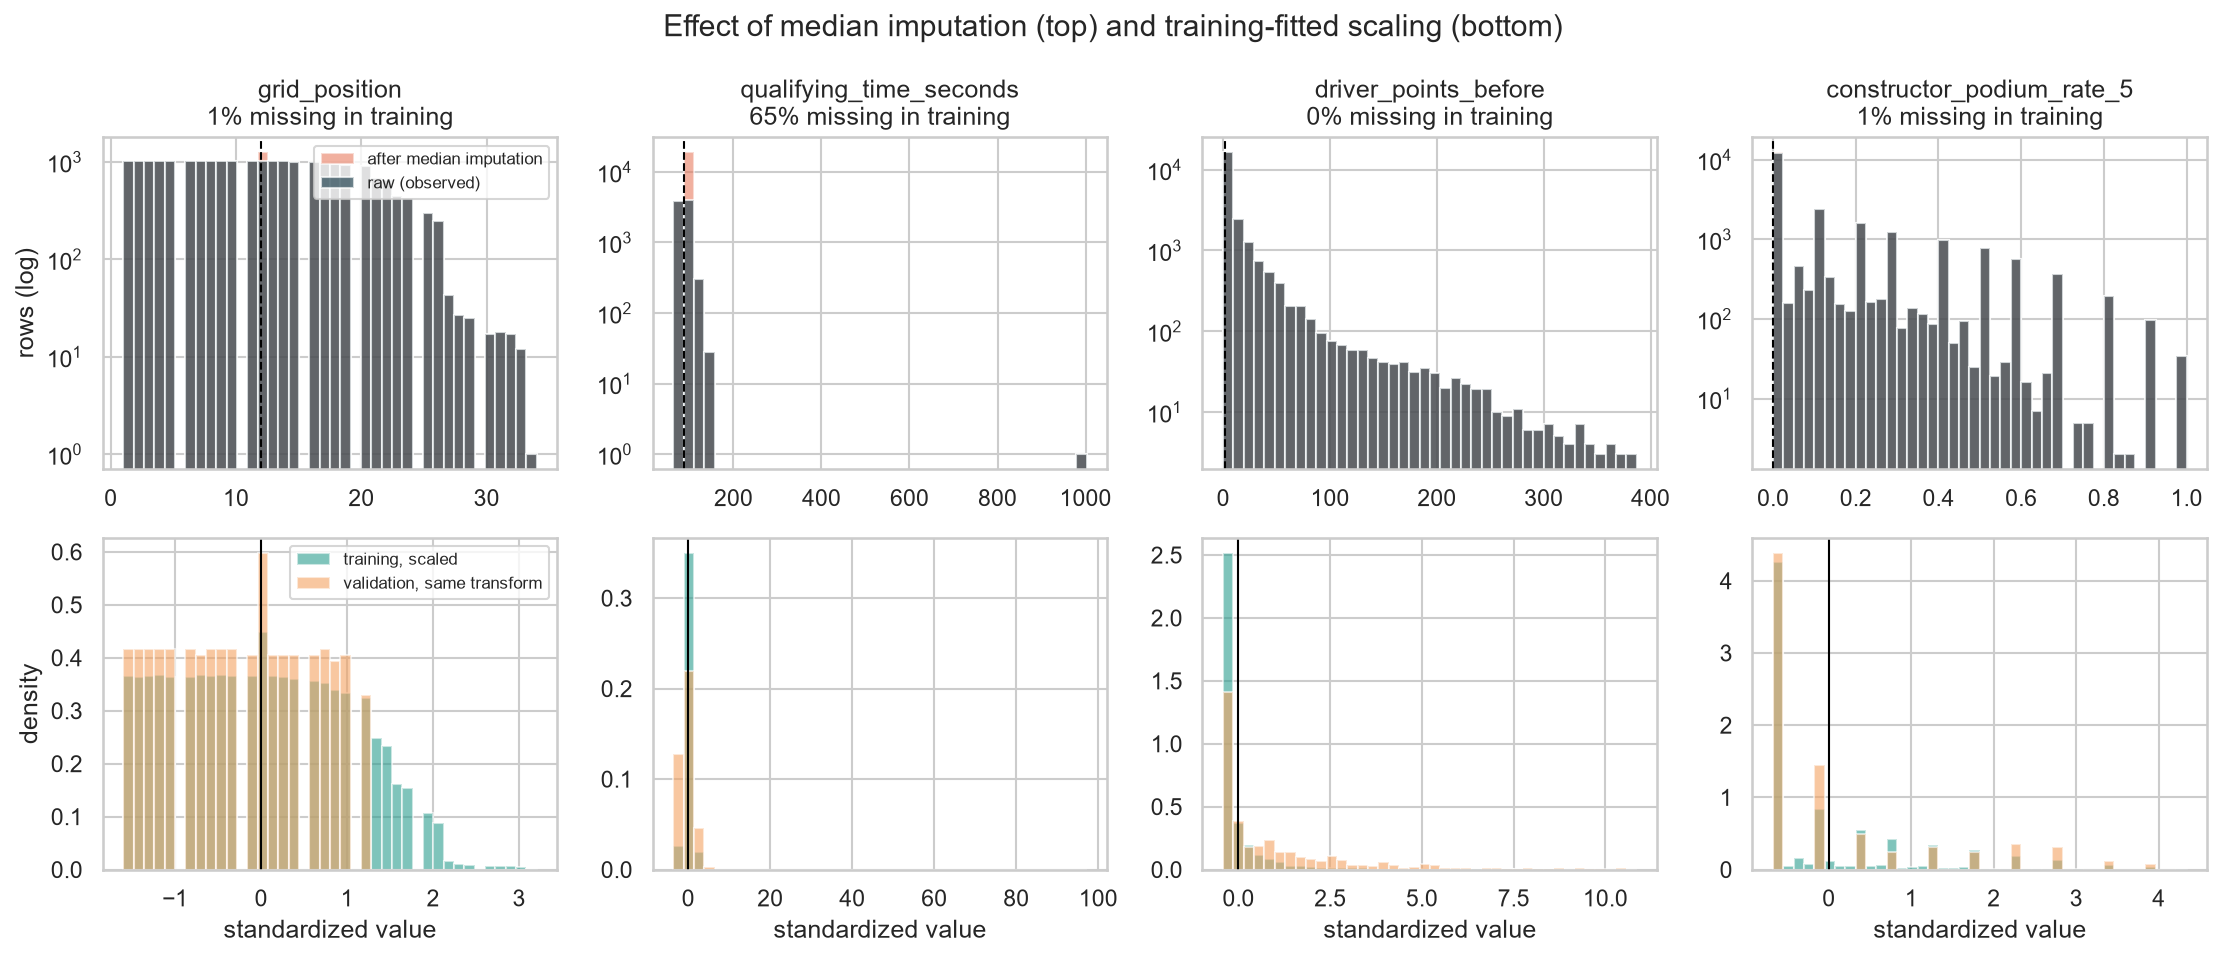

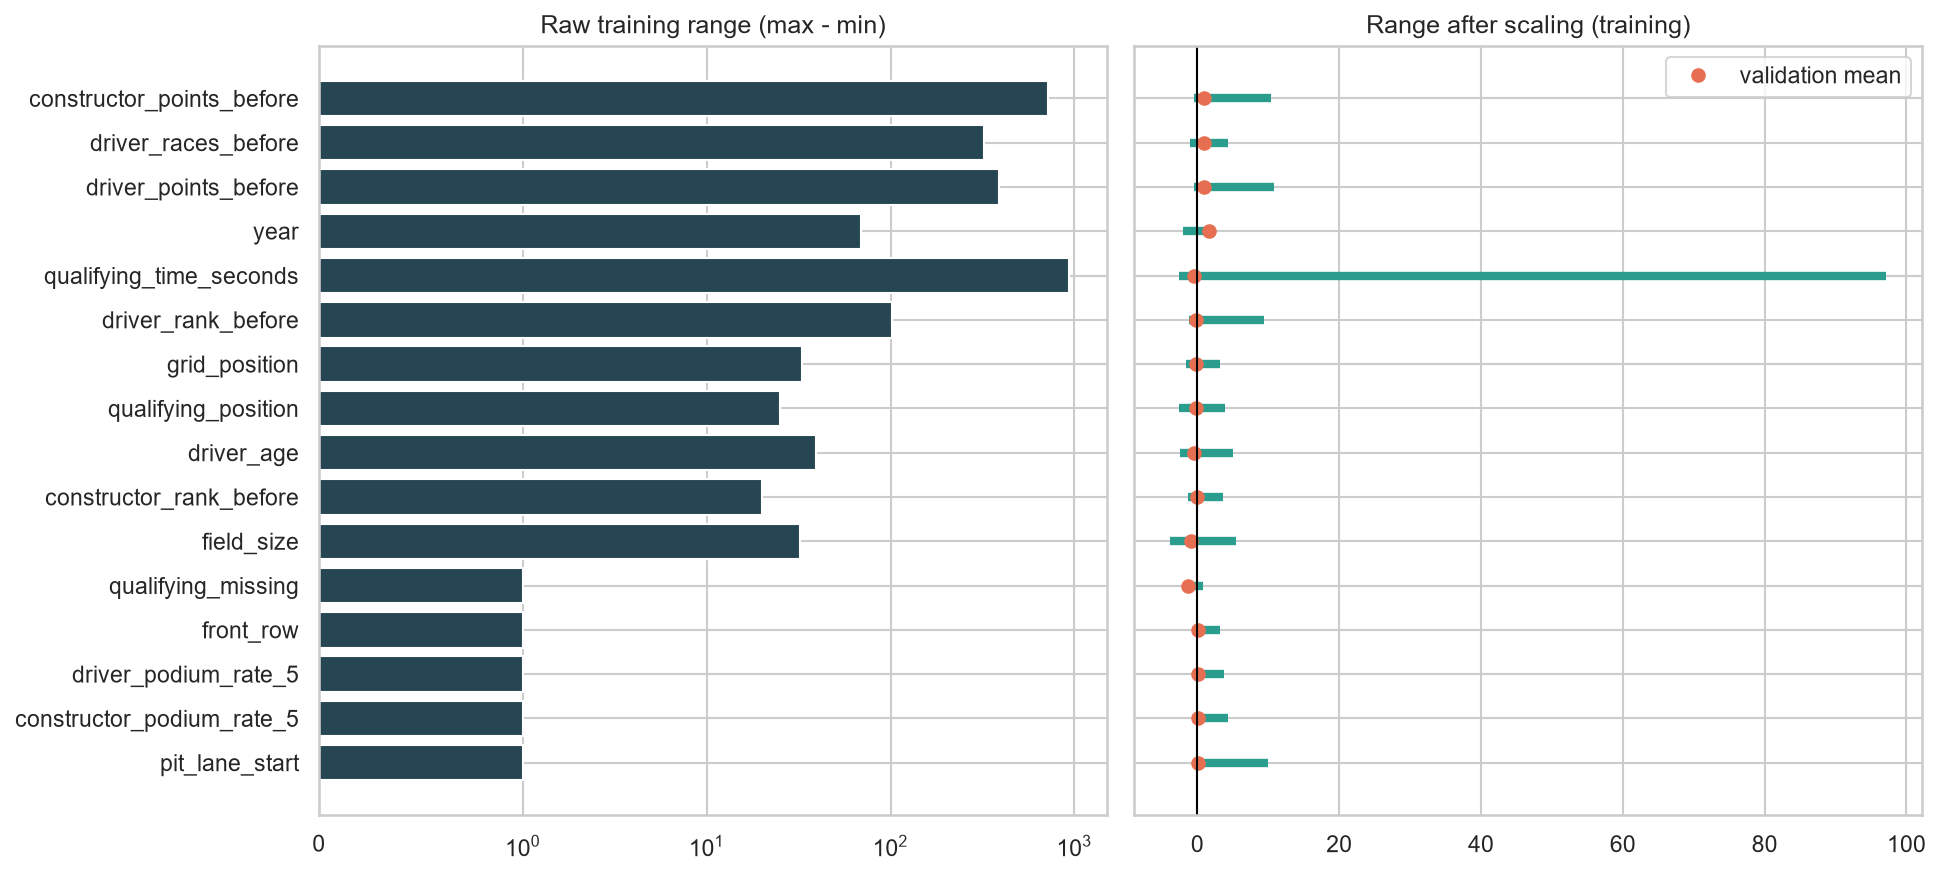

In [21]:
effects = results["preprocessing_effects"]
display(effects[["feature", "missing_share", "fill_value", "raw_min", "raw_max", "raw_mean", "raw_std",
                 "imputed_std", "std_change_from_imputation", "scaled_min", "scaled_max",
                 "scaled_mean", "scaled_std", "validation_scaled_mean", "test_scaled_mean"]].round(3))
display(Image(filename=str(OUT / "figures" / "preprocessing_distributions.png")))
display(Image(filename=str(OUT / "figures" / "preprocessing_ranges.png")))

**Median imputation** writes the training median into every missing cell. Qualifying position and time are missing in 64% of training rows, so they get a tall spike at the median and their standard deviation falls by about 40%. The other features with gaps (grid position and form) lose between 0% and 1%. Ranges do not change, because the median is inside the observed range. The `qualifying_missing` flag keeps the information that a value was filled.

**Standardization** moves every training feature to mean 0 and standard deviation 1. Raw ranges differ by orders of magnitude (`constructor_points_before` spans 0-722, the flags 0-1). After scaling they share one scale, so neither logistic regression's penalty nor the MLP's gradient steps are dominated by large-unit features. Scaling is linear, so the shape of each distribution and the order of values are unchanged. Long right tails stay long: one recorded qualifying time of 1002.6 s lands about 97 standard deviations out, and the points features reach about 11.

**Fitted on training only.** Validation and test pass through the training-fitted transform, so their means are *not* zero. `year` sits about +1.7 standard deviations from the training mean, prior points about +0.9, `field_size` about -1.0 (smaller modern grids), and `qualifying_missing` about -1.3 (qualifying is almost always recorded now). This is the honest view of period shift, and it is what the model sees at deployment.

## 13. Preprocessing experiments: strategy and order

In [22]:
display(results["preprocessing"])
order = results["preprocessing_order"]
display(order.round(4))
display(order.pivot_table(index=["experiment", "order", "preprocessing_fitted_on"], columns="model",
                          values="validation_PR-AUC").round(4))

,preprocessing,validation_ROC-AUC,validation_PR-AUC
0,median + scaling,0.925681,0.730083
1,"median, no scaling",0.925513,0.731371
2,zero + scaling,0.926841,0.726172


,experiment,order,preprocessing_fitted_on,model,missing_grid_position_becomes,missing_qualifying_time_becomes,train_std_qualifying_time,validation_PR-AUC,validation_ROC-AUC,PR-AUC_change_vs_reference
0,A: impute vs scale first,impute -> scale,train,Logistic regression,12.0000,87.2440,1.0000,0.7301,0.9257,0.0000
1,A: impute vs scale first,impute -> scale,train,Shallow neural network,12.0000,87.2440,1.0000,0.7166,0.9215,0.0000
2,A: impute vs scale first,scale -> impute,train,Logistic regression,12.0000,87.2440,0.5974,0.7301,0.9257,0.0000
3,A: impute vs scale first,scale -> impute,train,Shallow neural network,12.0000,87.2440,0.5974,0.7330,0.9250,0.0164
4,B: zero-fill vs scale first,zero-fill -> scale,train,Logistic regression,0.0000,0.0000,1.0000,0.7262,0.9268,0.0000
5,B: zero-fill vs scale first,zero-fill -> scale,train,Shallow neural network,0.0000,0.0000,1.0000,0.7401,0.9301,0.0000
6,B: zero-fill vs scale first,scale -> zero-fill,train,Logistic regression,12.0021,88.7834,0.5955,0.7304,0.9257,0.0043
7,B: zero-fill vs scale first,scale -> zero-fill,train,Shallow neural network,12.0021,88.7834,0.5955,0.7347,0.9249,-0.0054
8,C: split vs preprocess first,impute -> scale,all years (before split),Logistic regression,12.0000,86.6905,0.9686,0.7302,0.9257,0.0001
9,C: split vs preprocess first,impute -> scale,all years (before split),Shallow neural network,12.0000,86.6905,0.9686,0.7374,0.9257,0.0208


model                                                                     Logistic regression  \
experiment                   order              preprocessing_fitted_on                         
A: impute vs scale first     impute -> scale    train                                  0.7301   
                             scale -> impute    train                                  0.7301   
B: zero-fill vs scale first  scale -> zero-fill train                                  0.7304   
                             zero-fill -> scale train                                  0.7262   
C: split vs preprocess first impute -> scale    all years (before split)               0.7302   

model                                                                     Shallow neural network  
experiment                   order              preprocessing_fitted_on                           
A: impute vs scale first     impute -> scale    train                                     0.7166  
                             scale -> impute    train                                     0.7330  
B: zero-fill vs scale first  scale -> zero-fill train                                     0.7347  
                             zero-fill -> scale train                                     0.7401  
C: split vs preprocess first impute -> scale    all years (before split)                  0.7374

The first table compares preprocessing **strategies** (median with and without scaling, zero with scaling). The second reports three preprocessing-**order** experiments, each scored on validation with logistic regression and the shallow neural network:

- **A: impute → scale vs scale → impute.** Median imputation commutes with a linear rescale, so the missing value maps to the same raw median either way. The difference is the scaler's statistics: scaling first computes mean and spread from observed values only, so after imputation qualifying time has a training standard deviation of 0.60 instead of 1. Logistic regression moves by +0.0000; the MLP, which depends on input scale, moves by +0.016 validation PR-AUC.
- **B: zero-fill → scale vs scale → zero-fill.** Here the order changes the value. Filling zero *before* scaling writes a literal 0, which means "grid 0, ahead of pole" and "a 0-second qualifying lap". Filling zero *after* scaling writes the training mean (grid ≈ 12.0, qualifying ≈ 88.8 s). The `missing_..._becomes` columns show the fill in original units. Moving from the impossible raw zeros to the training mean changes the MLP by -0.005 PR-AUC and logistic regression by +0.0043.
- **C: preprocess before vs after the split.** Fitting the imputer and scaler on all seasons lets 2020-2024 set the medians and scaling used in training. Here it moved the MLP by +0.021 PR-AUC and logistic regression by +0.0001. Whatever the score, it uses future seasons, so the pipeline fits preprocessing inside the scikit-learn `Pipeline` on training rows only.

We keep split → median imputation → scaling for the linear model and the MLP, and median imputation without scaling for the forest.

### 13.1 Missing values: impute, drop columns, or drop rows?

About two thirds of training rows have no qualifying record, and form is missing on a driver's first race (standings are set to 0 before a driver's first race of a season, so they are not imputed). Instead of choosing by preference, each approach below is scored on the same 2020-2021 validation rows.

In [23]:
missing = results["missing_experiments"]
display(missing.round(4))
display(missing.pivot_table(index=["approach", "variant"], columns="model", values="PR-AUC_change_vs_used").round(4))

,variant,approach,train_rows,features,model,validation_PR-AUC,validation_ROC-AUC,PR-AUC_change_vs_used
0,median imputation (used),impute,23163,16,Logistic regression,0.7301,0.9257,0.0000
1,median imputation (used),impute,23163,16,Shallow neural network,0.7166,0.9215,0.0000
2,mean imputation,impute,23163,16,Logistic regression,0.7304,0.9257,0.0003
3,mean imputation,impute,23163,16,Shallow neural network,0.7066,0.9196,-0.0100
4,KNN imputation (k=5),impute,23163,16,Logistic regression,0.7277,0.9258,-0.0024
5,KNN imputation (k=5),impute,23163,16,Shallow neural network,0.7326,0.9259,0.0160
6,iterative (regression) imputation,impute,23163,16,Logistic regression,0.7280,0.9269,-0.0021
7,iterative (regression) imputation,impute,23163,16,Shallow neural network,0.7336,0.9265,0.0169
8,"median, without the qualifying_missing flag",flag,23163,15,Logistic regression,0.7294,0.9253,-0.0007
9,"median, without the qualifying_missing flag",flag,23163,15,Shallow neural network,0.7113,0.9248,-0.0053


model                                                            Logistic regression  \
approach     variant                                                                   
drop columns drop the sparse columns (qualifying_position, q...              -0.0059   
drop rows    drop training rows with any missing feature                      0.0014   
             drop training rows with no qualifying (keeps 19...              -0.0011   
flag         median, without the qualifying_missing flag                     -0.0007   
impute       KNN imputation (k=5)                                            -0.0024   
             iterative (regression) imputation                               -0.0021   
             mean imputation                                                  0.0003   
             median imputation (used)                                         0.0000   

model                                                            Shallow neural network  
approach     variant                                                                     
drop columns drop the sparse columns (qualifying_position, q...                 -0.0305  
drop rows    drop training rows with any missing feature                         0.0221  
             drop training rows with no qualifying (keeps 19...                 -0.0111  
flag         median, without the qualifying_missing flag                        -0.0053  
impute       KNN imputation (k=5)                                                0.0160  
             iterative (regression) imputation                                   0.0169  
             mean imputation                                                    -0.0100  
             median imputation (used)                                            0.0000

**Imputers.** Mean, k-nearest-neighbour, and iterative regression imputation change logistic regression's validation PR-AUC by +0.0003, -0.0024, and -0.0021 against median imputation. For the network the changes are -0.010, +0.016, and +0.017. These network numbers come from a single seed, and a single seed can sit 0.021 away from its own average (section 10.3), so changes of this size are within noise.

**Dropping columns.** Removing the two columns with more than 50% missing values (`qualifying_position` and `qualifying_time_seconds`) changes the score by -0.006 for logistic regression and -0.030 for the network. Removing the `qualifying_missing` flag instead changes logistic regression by -0.0007 and the network by -0.005.

**Dropping rows.** Keeping only training rows with qualifying data (1994 onward) leaves 8,348 of 23,163 rows and changes the score by -0.001 (logistic regression) and -0.011 (network). Keeping only complete rows leaves 8,054 and changes it by +0.001 and +0.022. Dropping rows throws away about two thirds of the history, including most of the long driver and team form.

**Decision.** Median imputation plus the missing-indicator flag, fitted on training rows only, keeps all 23,163 training rows and is never meaningfully beaten. We judge it on logistic regression, the selected model, because it has no random seed: every alternative is within 0.0059 of median imputation. The network's single-seed changes run from -0.030 to +0.022. One seed can move by 0.021 on its own, so these numbers cannot rank the imputers. Only the -0.030 from dropping the qualifying columns stands out, and it argues against dropping them. We keep median imputation. Leaving the nulls, dropping columns, and dropping rows were all tested against it, and none of them helped enough to justify what it throws away, such as the two thirds of training history lost when rows are dropped.

## 14. Model comparison: train, validation, and unseen test

,model,split,threshold,ROC-AUC,PR-AUC,F1,Precision,Recall
0,Logistic regression,train,0.625,0.899412,0.562426,0.577853,0.461285,0.773260
1,Logistic regression,validation,0.625,0.925681,0.730083,0.699620,0.630137,0.786325
2,Logistic regression,test,0.625,0.934984,0.702333,0.664234,0.529070,0.892157
3,Random forest,train,0.775,0.927204,0.645605,0.603730,0.607307,0.600195
4,Random forest,validation,0.775,0.925140,0.712461,0.701299,0.710526,0.692308
5,Random forest,test,0.775,0.936716,0.717337,0.655087,0.663317,0.647059
6,Shallow neural network,train,0.455,0.902393,0.576420,0.525175,0.603463,0.464867
7,Shallow neural network,validation,0.455,0.921543,0.716616,0.710280,0.783505,0.649573
8,Shallow neural network,test,0.455,0.932692,0.715741,0.626039,0.719745,0.553922


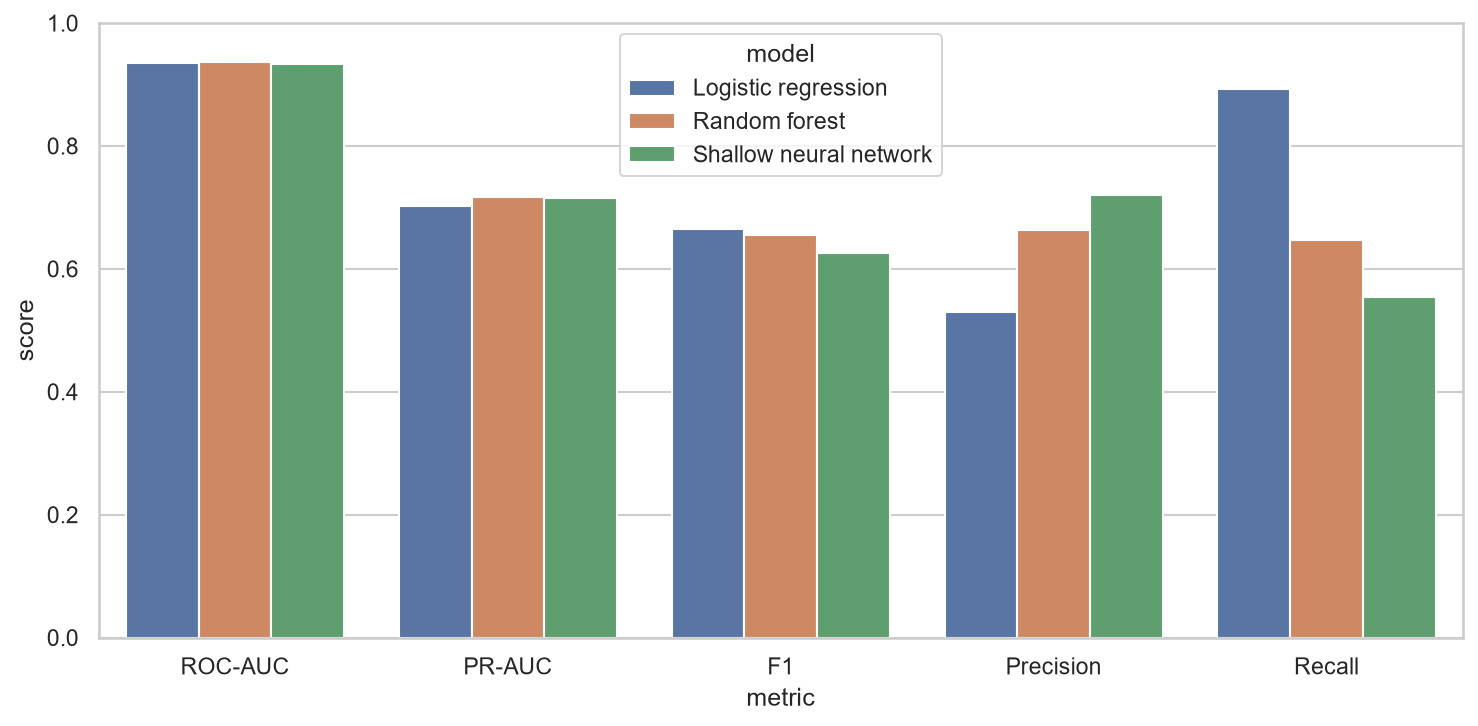

Validation-only model selection ranking:


,model,split,threshold,ROC-AUC,PR-AUC,F1,Precision,Recall
1,Logistic regression,validation,0.625,0.925681,0.730083,0.699620,0.630137,0.786325
7,Shallow neural network,validation,0.455,0.921543,0.716616,0.710280,0.783505,0.649573
4,Random forest,validation,0.775,0.925140,0.712461,0.701299,0.710526,0.692308


In [24]:
display(results["metrics"])
display(Image(filename=str(OUT / "figures" / "model_comparison.png")))
validation_ranking = (results["metrics"].query("split == 'validation'")
                      .sort_values("PR-AUC", ascending=False))
print("Validation-only model selection ranking:")
display(validation_ranking)

Logistic regression is the statistical baseline, random forest captures nonlinear interactions, and the two-hidden-layer MLP is the shallow neural network. PR-AUC is the selection metric because the positive class is uncommon. Model-specific thresholds (0.625, 0.775, and 0.455) maximize validation F1 and are frozen before test scoring. All three models score lower on training than on validation, which reflects historical distribution shift (a lower podium rate, 13.3% against 15.0%, and far more missing qualifying in the training years). The forest only behaves this way because its depth and leaf size were limited by the validation search in section 14.1; its first settings memorized the training seasons.

### 14.1 Hyperparameter search and an honest improvement attempt for each model

Every setting was trained on 1950-2019 and scored on 2020-2021 only; the test seasons were not touched. The network is averaged over three random seeds, because its score changes with the initialization.

In [25]:
tuning = results["tuning"]
display(tuning[["model", "settings", "is_initial", "is_current", "validation_PR-AUC", "validation_PR-AUC_std",
                "validation_ROC-AUC", "train_PR-AUC", "rank_within_model"]].round(4))

,model,settings,is_initial,is_current,validation_PR-AUC,validation_PR-AUC_std,validation_ROC-AUC,train_PR-AUC,rank_within_model
0,Logistic regression,"{'C': 1.0, 'penalty': 'l1'}",False,False,0.7303,0.0000,0.9257,0.5623,1
1,Logistic regression,"{'C': 10.0, 'penalty': 'l1'}",False,False,0.7301,0.0000,0.9257,0.5624,2
2,Logistic regression,"{'C': 1.0, 'penalty': 'l2'}",True,True,0.7301,0.0000,0.9257,0.5624,3
3,Logistic regression,"{'C': 10.0, 'penalty': 'l2'}",False,False,0.7301,0.0000,0.9257,0.5624,4
4,Logistic regression,"{'C': 0.1, 'penalty': 'l2'}",False,False,0.7299,0.0000,0.9260,0.5626,5
5,Logistic regression,"{'C': 0.1, 'penalty': 'l1'}",False,False,0.7264,0.0000,0.9257,0.5621,6
6,Logistic regression,"{'C': 0.01, 'penalty': 'l2'}",False,False,0.7248,0.0000,0.9260,0.5638,7
7,Logistic regression,"{'C': 0.01, 'penalty': 'l1'}",False,False,0.7099,0.0000,0.9234,0.5608,8
8,Random forest,"{'max_depth': None, 'min_samples_leaf': 12}",False,False,0.7160,0.0000,0.9246,0.7369,1
9,Random forest,"{'max_depth': 12, 'min_samples_leaf': 30}",False,True,0.7125,0.0000,0.9251,0.6456,2


**Random forest: improved.** The starting forest (unlimited depth, leaf size 4) scored 0.709 on validation but 0.917 on training, a memorized fit. The search ranked it 5th of 9. Depth 12 with leaf size 30 scores 0.712 on validation and ranks 2nd of 9. The best setting ({'max_depth': None, 'min_samples_leaf': 12}) is only 0.004 higher, far inside the validation noise shown in section 11.1, so we keep the depth limit as the more constrained model. Its training PR-AUC falls from 0.917 to 0.646, so it no longer memorizes the training seasons. The test set did not influence the choice.

**Shallow neural network: a noisy search.** We tried one hidden layer of 8, 16, 32, and 64 units and two layers (32, 12) and (64, 32), each with two regularization strengths, every one averaged over three seeds. The adopted two-layer (32, 12) network with alpha 0.02 scores 0.7228 and ranks 7th of 12, against 0.7179 for the starting alpha of 0.002. The best setting ({'hidden_layer_sizes': (64,), 'alpha': 0.002}) scores 0.7362, only 0.013 higher, while the seed spread of a single setting reaches 0.025 in this search. The ranking is also unstable: with `round` in the features, the adopted setting ranked first. Chasing the top of a ranking that moves with one input and one seed would be selecting noise, so we keep the adopted network. Small networks with 8 units are clearly worse, so the network is not a deliberately weak model.

**Logistic regression: insensitive.** L1 and L2 penalties and C from 0.01 to 10 all fall between 0.710 and 0.730. The starting C = 1 with L2 ties for best (within 0.0005), so we keep it.

**A caution about the headline number.** The network's 0.7166 validation score in section 14 comes from seed 42. Averaged over three seeds the same setting scores 0.7228, with a seed standard deviation of 0.005, which is below logistic regression's 0.7301. Logistic regression is highest on validation by the seed-42 table and by the three-seed average, so the selection does not depend on the seed. The validation gaps between the three models are at most 0.018, and the bootstrap in section 11.1 shows they sit inside the race-to-race noise.

### 14.2 Does the added complexity earn its place?

In [26]:
display(results["test_uncertainty"].round(4))

,comparison,test_PR-AUC,ci_low_2.5%,ci_high_97.5%,races
0,Logistic regression,0.7023,0.6465,0.7606,68
1,Random forest,0.7173,0.6605,0.7780,68
2,Shallow neural network,0.7157,0.6619,0.7737,68
3,Random forest minus Logistic regression,0.0150,-0.0119,0.0462,68
4,Shallow neural network minus Logistic regression,0.0134,-0.0162,0.0444,68


On unseen test seasons (2022-2024) PR-AUC is 0.702 for logistic regression, 0.717 for the random forest and 0.716 for the network; ROC-AUC is 0.935, 0.937 and 0.933. The forest and the network are level at the top, and logistic regression is about 0.013 behind. To see whether that gap is real we bootstrapped the 68 test races (table above). The bootstrap resamples predictions we already had and chooses nothing, and we ran it after every choice was frozen. The forest minus logistic regression difference is +0.0150 with an interval of -0.012 to +0.046, and for the network it is +0.0134 with an interval of -0.016 to +0.044. Both intervals include zero, and so do the validation intervals in section 11.1. **The data do not support claiming that a more complex model is better.**

We therefore treat the three models as equivalent in ranking quality and use the other properties to decide. Logistic regression is the baseline and the easiest to defend and explain: its coefficients are directly readable, it is stable across seeds, and it needs no tuning to behave. It is also nominally highest on validation PR-AUC, the score we select on, so logistic regression is the selected model and the one used for the inference demo. On test the forest and the network are slightly higher, but the bootstrap shows that edge is within noise, and the test seasons are never used to choose. The reason a nonlinear model gains so little is that the strongest signals (grid, qualifying position, and recent form) act close to monotonically on podium odds, which a linear model already captures. PR-AUC is primary because only about one in eight entrants finishes on the podium, so ROC-AUC rewards correctly ranking the many easy non-podium rows; ROC-AUC stays as the secondary metric.

## 15. Feature-group ablation

,variant,features,validation_PR-AUC,validation_ROC-AUC,PR-AUC_change
0,all features,16,0.730083,0.925681,0.000000
1,without grid,12,0.704734,0.920331,-0.025349
2,without qualifying,13,0.724015,0.923992,-0.006068
3,without form,13,0.713623,0.920847,-0.016460
4,without standings,12,0.712738,0.923528,-0.017345
5,without context,14,0.728782,0.925191,-0.001301


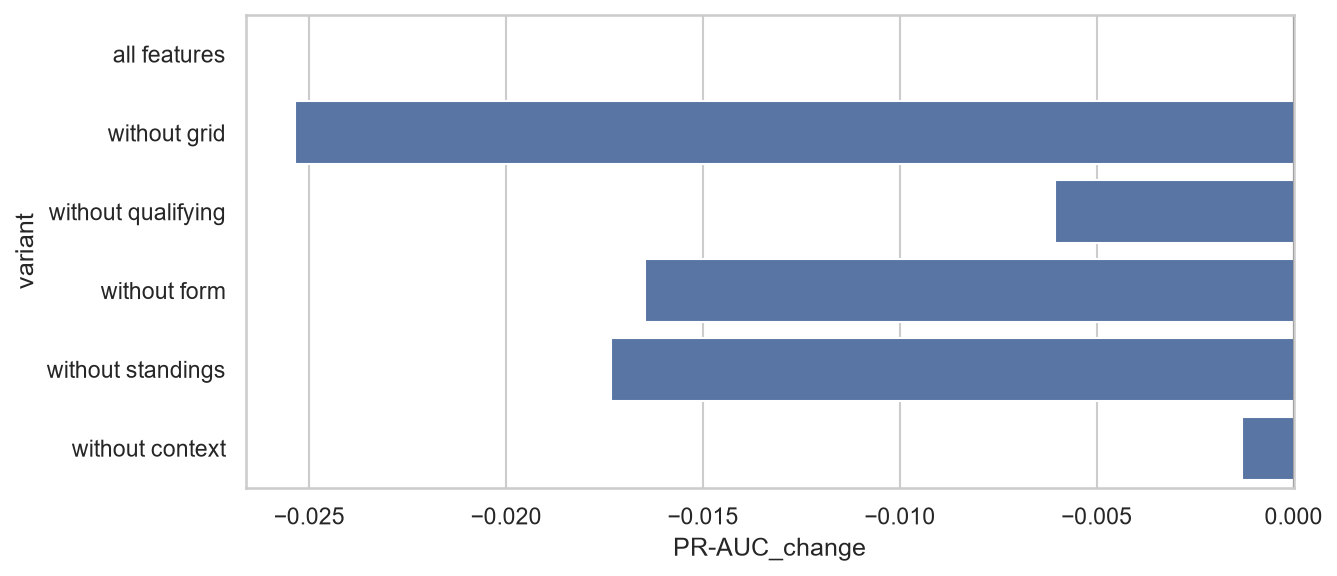

In [27]:
display(results["ablations"])
display(Image(filename=str(OUT / "figures" / "ablation.png")))

Each experiment removes one complete feature group and retrains the logistic baseline. The change from full-model validation PR-AUC measures the group's incremental predictive contribution after training and complements the earlier exploratory motivation.

## 16. Global and local explainability

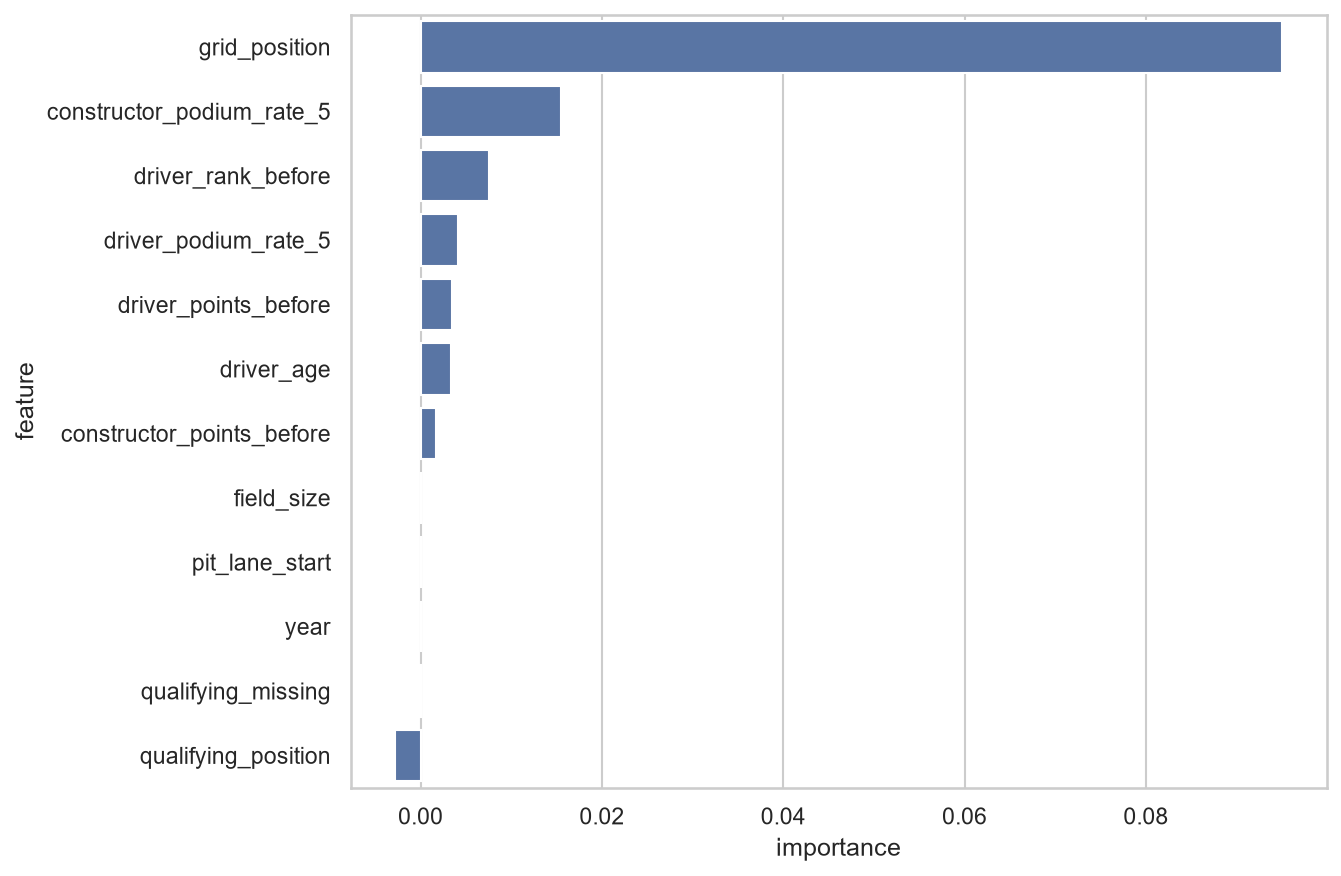

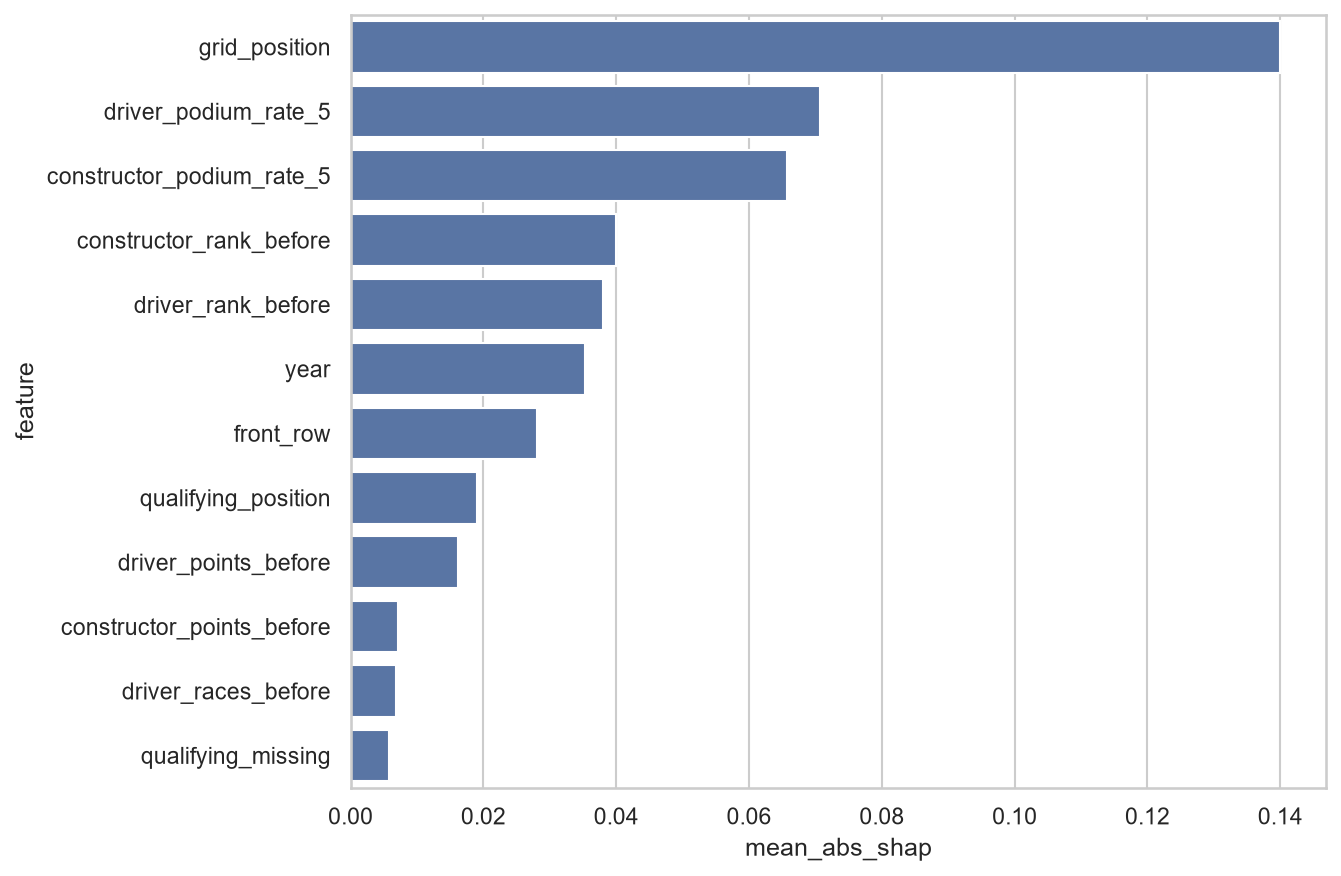

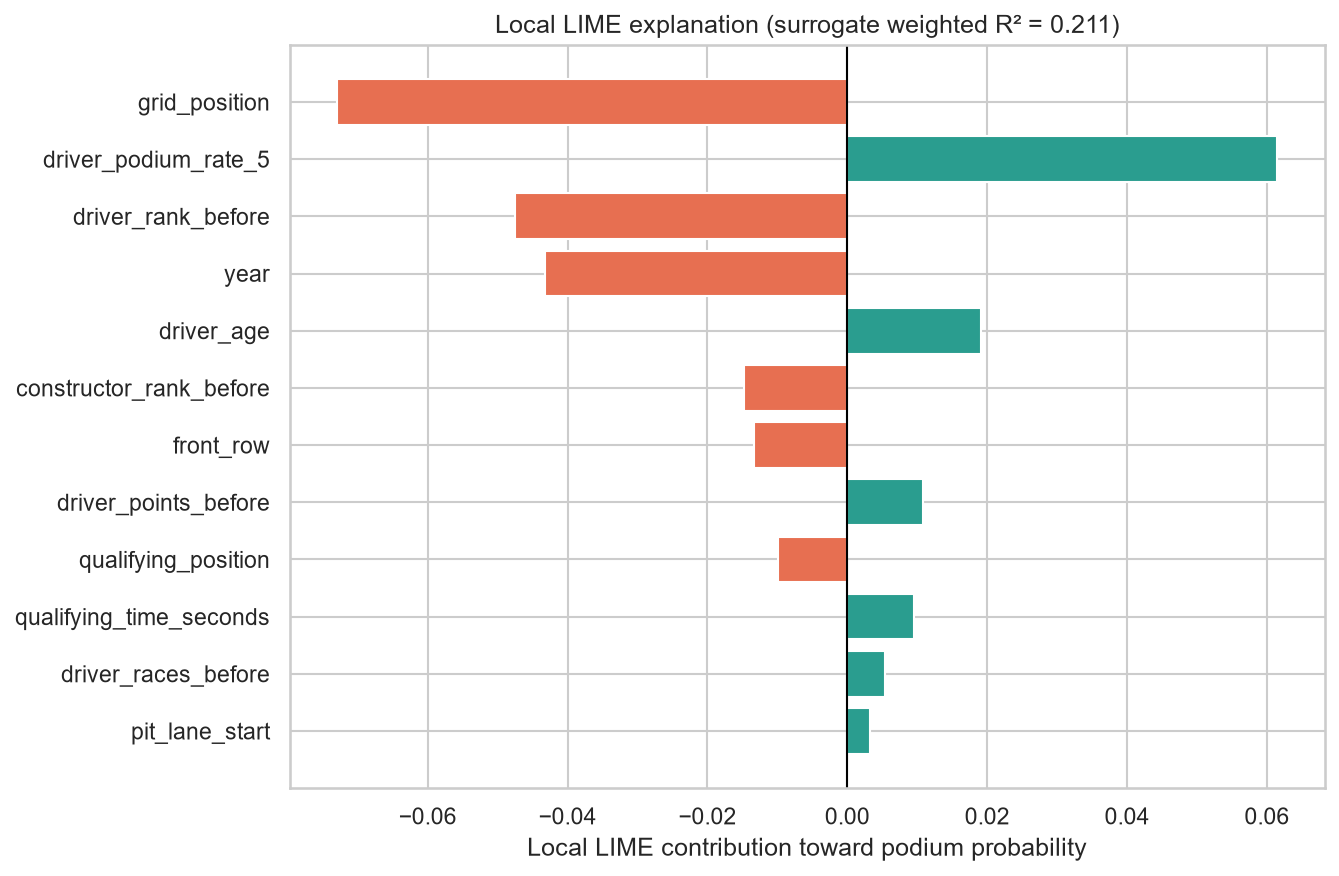

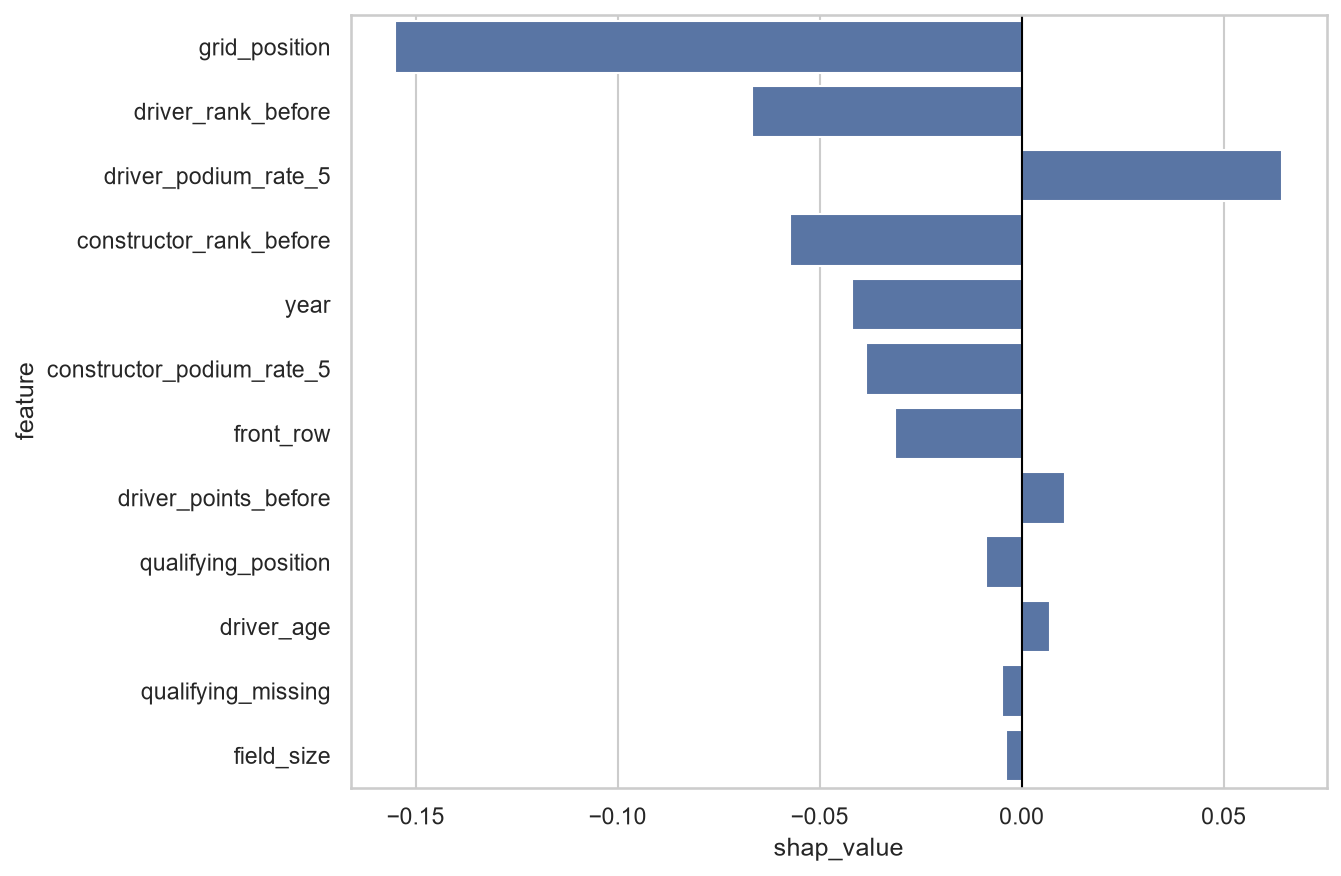

,feature,mean_abs_shap
0,grid_position,0.139958
7,driver_podium_rate_5,0.070646
8,constructor_podium_rate_5,0.065697
13,constructor_rank_before,0.039929
11,driver_rank_before,0.037958
15,year,0.035273
2,front_row,0.028118
4,qualifying_position,0.019023
10,driver_points_before,0.016174
12,constructor_points_before,0.007213


,feature,lime_weight,observed_value,model_probability,surrogate_probability,local_fidelity_r2
0,grid_position,-0.072995,11.0,0.174288,0.173884,0.210586
7,driver_podium_rate_5,0.061505,0.2,0.174288,0.173884,0.210586
11,driver_rank_before,-0.047447,15.0,0.174288,0.173884,0.210586
15,year,-0.043176,2021,0.174288,0.173884,0.210586
14,driver_age,0.019060,23.554214,0.174288,0.173884,0.210586
13,constructor_rank_before,-0.014842,8.0,0.174288,0.173884,0.210586
2,front_row,-0.013363,0,0.174288,0.173884,0.210586
10,driver_points_before,0.010819,13.0,0.174288,0.173884,0.210586
4,qualifying_position,-0.009943,11.0,0.174288,0.173884,0.210586
5,qualifying_time_seconds,0.009554,70.332,0.174288,0.173884,0.210586


,feature,shap_value,observed_value
0,grid_position,-0.155097,11.0
11,driver_rank_before,-0.066778,15.0
7,driver_podium_rate_5,0.064479,0.2
13,constructor_rank_before,-0.057311,8.0
15,year,-0.042059,2021
8,constructor_podium_rate_5,-0.038605,0.1
2,front_row,-0.031273,0
10,driver_points_before,0.010759,13.0
4,qualifying_position,-0.008841,11.0
14,driver_age,0.007045,23.554214


In [28]:
for figure in ["permutation_importance", "shap_global", "lime_local", "shap_local"]:
    display(Image(filename=str(OUT / "figures" / f"{figure}.png")))
display(results["shap_global"].head(12))
display(results["lime_local"].head(12))
display(results["shap_local"].head(12))

Permutation importance measures the validation PR-AUC change after shuffling one feature, and global SHAP summarizes average contribution magnitude. Local LIME explains one fixed validation prediction with 5,000 perturbations around that row and a distance-weighted ridge surrogate; its weighted R² reports local fidelity. Positive LIME weights push the surrogate toward a podium and negative weights push it away. Local SHAP is retained as a supplementary cross-check. Correlated predictors can divide importance differently across methods. These values describe fitted-model reliance and are **not causal effects**.

## 17. Complete and partially missing inference

In [29]:
display(results["summary"]["inference_demos"])

{'model': 'Logistic regression',
 'complete_record': {'podium_probability': 0.9064506005148444,
  'predicted_podium': True,
  'threshold': 0.6250000000000001},
 'partial_record': {'podium_probability': 0.38742525704038905,
  'predicted_podium': False,
  'threshold': 0.6250000000000001}}

The complete example follows the normal inference path. The partial example demonstrates that missing inputs are handled by the imputer fitted on training seasons, without consulting validation or test data. Its output demonstrates software robustness rather than a historical base rate.

## 18. Limitations

- Qualifying coverage is sparse and era-dependent in older seasons.
- Regulations, field size, reliability, and competitive structure change over time.
- Constructor identifiers do not bridge team renames, and a few old identifiers are reused by unrelated later teams (section 10.4).
- The nationality-to-country mapping is incomplete and cannot represent multiple nationalities.
- Mechanical status classification is rules-based and can miss ambiguous causes.
- Validation contains only the 2020-2021 seasons, so selection estimates have sampling uncertainty.
- Probabilities were evaluated for ranking and threshold classification, not formal calibration.
- Permutation importance, SHAP, and LIME explain associations inside fitted models, not causes of podium finishes.